# IA prudente guidée par le contexte patient — classification des lésions cutanées (HAM10000)

**TP « Advanced Applications of Data Science in Medicine »** — USTO-MB, Oran — groupe de 3 étudiants.

> **Question de recherche.** Une IA *prudente* — qui utilise le contexte du patient pour interpréter l'image, tient
> compte du coût d'un mélanome manqué et sait s'abstenir quand elle est incertaine — est-elle meilleure et plus sûre
> qu'un classifieur classique ?

| Modèle | Entrées | Idée |
|---|---|---|
| **M1** | image | EfficientNet-B0 pré-entraîné (baseline imposée par la fiche) |
| **M2** | clinique | XGBoost sur âge, sexe, localisation |
| **M3** | image + clinique | fusion précoce : caractéristiques CNN **concaténées** au contexte |
| **M4** | image + clinique | fusion tardive : moyenne pondérée des probabilités de M1 et M2 |
| **M5** (proposé) | image + clinique | **FiLM** : le contexte module chaque canal de l'image (γ, β) + perte pondérée + **seuil de coût** |
| **M5 + abstention** | — | **prédiction conforme** : l'IA renvoie au médecin les cas incertains |

Le notebook suit les **10 points de la fiche**. Le code est dans `src/` ; les figures et tableaux dans `resultats/`.
Par défaut (`RUN_TRAINING = False`), il **relit les prédictions sauvegardées** des 19 entraînements et recalcule
tout le reste (décisions, métriques, bootstrap, figures). Aucun chiffre n'est écrit à la main : tout vient des
fichiers produits par le code.

In [1]:
# --- Configuration : fonctionne en local (Windows/Linux) et sur Google Colab ---------------
import os, sys, subprocess, contextlib, io, json
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/Skin_Cancer/projet")            # ← à adapter
    os.environ["HAM_DIR"] = "/content/drive/MyDrive/Skin_Cancer/HAM10000"  # ← à adapter
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], check=True)
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT); sys.path.insert(0, str(PROJECT))

RUN_TRAINING = False   # True : réentraîne tout (~2 h sur RTX 3050) ; False : relit les prédictions sauvegardées

import numpy as np, pandas as pd, torch
from IPython.display import Image, display, Markdown
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 60)
from src import config as C

def fig(name, width=950):
    display(Image(filename=str(C.FIG_DIR / f"{name}.png"), width=width))

def tab(name, **kw):
    return pd.read_csv(C.TAB_DIR / f"{name}.csv", **kw)

def quiet(f, *a, **k):
    """Exécute f en masquant ses impressions (les tableaux sont affichés ensuite)."""
    with contextlib.redirect_stdout(io.StringIO()):
        return f(*a, **k)

print("Projet :", PROJECT)
print("Données :", C.DATA_DIR, "| GPU :", torch.cuda.is_available(),
      torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

Projet : C:\Users\adel\Desktop\Skin_Cancer\projet
Données : C:\Users\adel\Desktop\Skin_Cancer\HAM10000 | GPU : True NVIDIA GeForce RTX 3050 Laptop GPU


## Étape 1 — Comprendre le problème médical et les données

**Le problème.** Le mélanome est le cancer cutané le plus meurtrier : ~325 000 nouveaux cas dans le monde en 2020 et
une projection de 510 000 cas et 96 000 décès par an en 2040 [Arnold 2022]. Pris tôt, il se traite par exérèse. Le
dermatologue examine la lésion au **dermoscope** et décide : surveiller, retirer, biopsier. La plupart des lésions
pigmentées sont bénignes (nævus, kératoses) et certains mélanomes ressemblent à des nævus.

**Le médecin ne regarde pas l'image seule** : l'âge, la localisation et le sexe changent son interprétation (un nævus
qui apparaît à 70 ans inquiète plus qu'à 20 ans ; les kératoses actiniques siègent sur les zones photo-exposées).
**Les erreurs n'ont pas le même coût** : manquer un mélanome retarde le traitement d'un cancer ; une fausse alerte
coûte une consultation ou une biopsie. Une IA utile doit en tenir compte, et **savoir dire « je ne sais pas »**.

**Les données.** HAM10000 [Tschandl 2018] : 10 015 images dermoscopiques de 7 470 lésions (Vienne, Autriche et
Queensland, Australie), 7 diagnostics : `nv` nævus (bénin), `mel` **mélanome (malin)**, `bkl` kératose bénigne,
`bcc` **carcinome basocellulaire (malin)**, `akiec` **kératose actinique / Bowen (pré-malin / in situ)**, `vasc` lésion
vasculaire, `df` dermatofibrome. Contexte : `age`, `sex`, `localization`. La colonne `dx_type` (méthode de
confirmation du diagnostic) **n'est jamais utilisée comme entrée** : elle trahit la réponse (voir étape 2).

**Ce qui rend le problème difficile** : déséquilibre (67 % de nævus — un modèle qui dit toujours « nævus » a 67 %
d'exactitude et ne trouve aucun cancer), plusieurs images par lésion (risque de fuite), vérité terrain hétérogène
(histologie pour ~la moitié seulement), contexte clinique pauvre (3 variables).

*Sources : [Tschandl 2018] Sci Data 5:180161, doi:10.1038/sdata.2018.161 ; [Arnold 2022] JAMA Dermatol
158(5):495-503 ; [Codella 2019] arXiv:1902.03368 (défi ISIC 2018).*

## Étape 2 — Explorer les deux modalités

*Skills utilisés : `data:explore-data` (profil des colonnes, qualité) et `dataviz` (palette validée pour daltoniens,
une couleur par entité, mise en avant du mélanome).* Les fichiers `hmnist_*.csv` (images 28×28 aplaties) sont ignorés.

In [2]:
from src.data import load_metadata
from src.eda import run_eda
meta = load_metadata()
eda = run_eda(meta)
print(f"{len(meta)} images, {meta.lesion_id.nunique()} lésions, colonnes : {list(meta.columns[:7])}")
display(eda["profil"])
display(eda["classes"])

10015 images, 7470 lésions, colonnes : ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


,colonne,type,manquants,« unknown »,valeurs distinctes,plus fréquentes
0,lesion_id,str,0,0,7470,"HAM_0000835 (6), HAM_0003789 (6), HAM_0001863 (6)"
1,image_id,str,0,0,10015,"ISIC_0024306 (1), ISIC_0024307 (1), ISIC_0024308 (1)"
2,dx,str,0,0,7,"nv (6705), mel (1113), bkl (1099)"
3,dx_type,str,0,0,4,"histo (5340), follow_up (3704), consensus (902)"
4,age,float64,57,0,18,"45.0 (1299), 50.0 (1187), 55.0 (1009)"
5,sex,str,0,57,3,"male (5406), female (4552), unknown (57)"
6,localization,str,0,234,15,"back (2192), lower extremity (2077), trunk (1404)"


,images,lesions,% images,images / lésion
dx,,,,
nv,6705,5403,66.9,1.24
mel,1113,614,11.1,1.81
bkl,1099,727,11.0,1.51
bcc,514,327,5.1,1.57
akiec,327,228,3.3,1.43
vasc,142,98,1.4,1.45
df,115,73,1.1,1.58


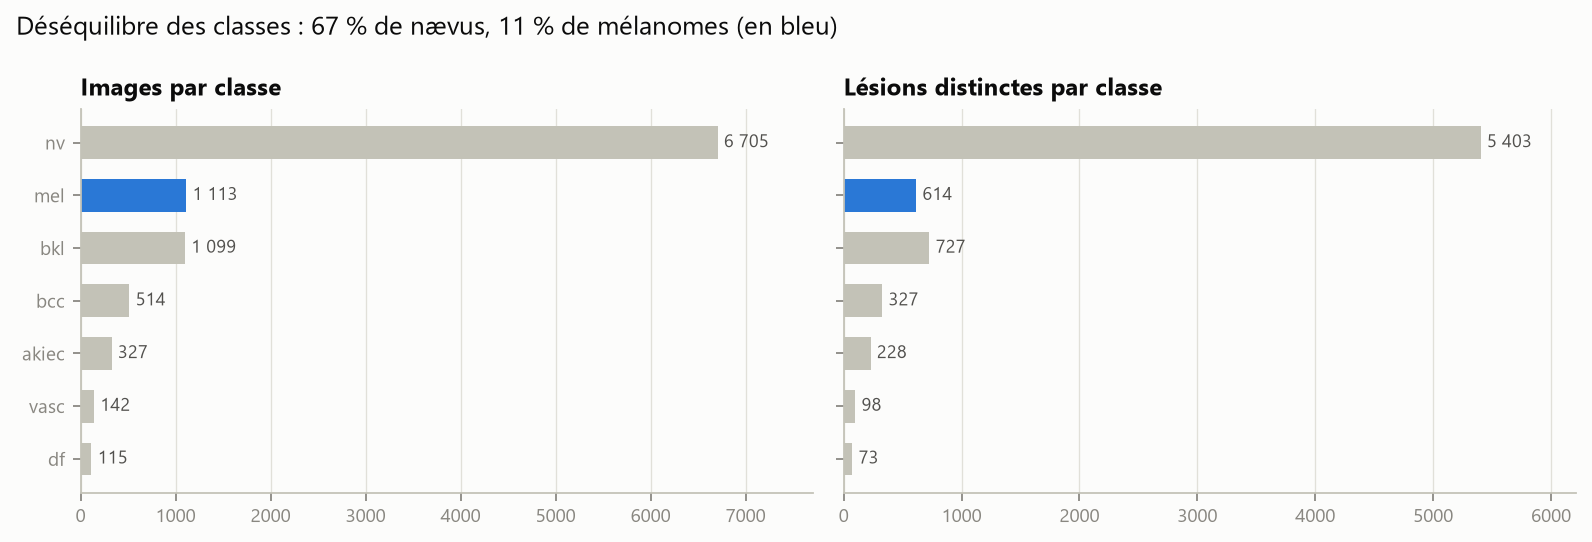

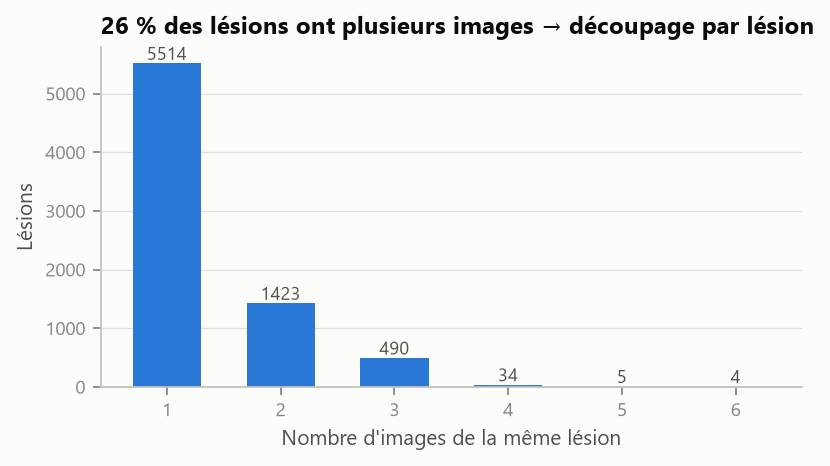

In [3]:
fig("02_classes"); fig("02_images_par_lesion", 600)

Âge : {'count': 9958.0, 'mean': 51.9, 'std': 17.0, 'min': 0.0, '25%': 40.0, '50%': 50.0, '75%': 65.0, 'max': 85.0} | âges = 0 : 39 | part des âges multiples de 5 : 1.0


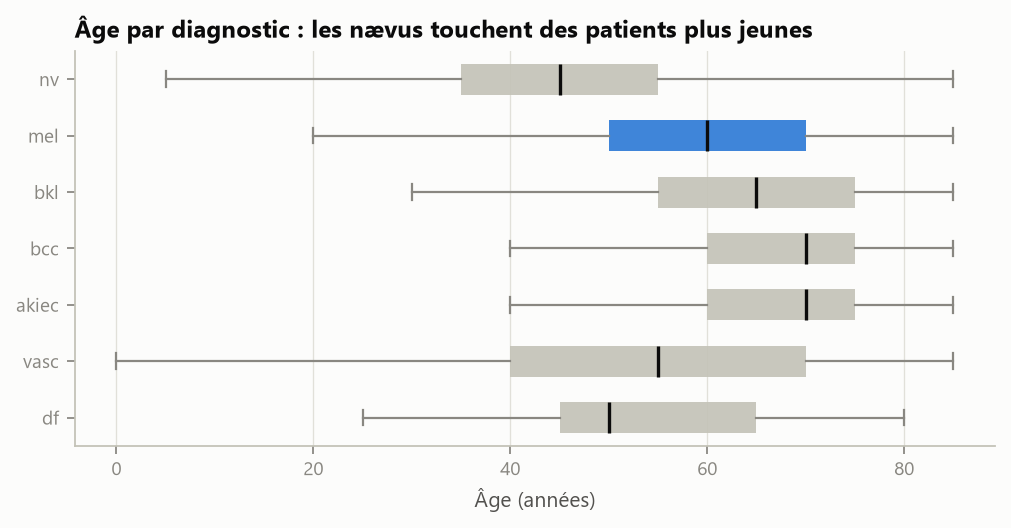

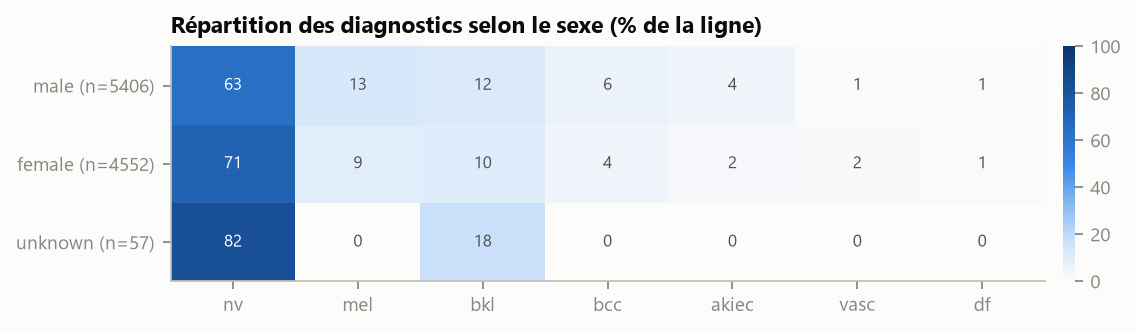

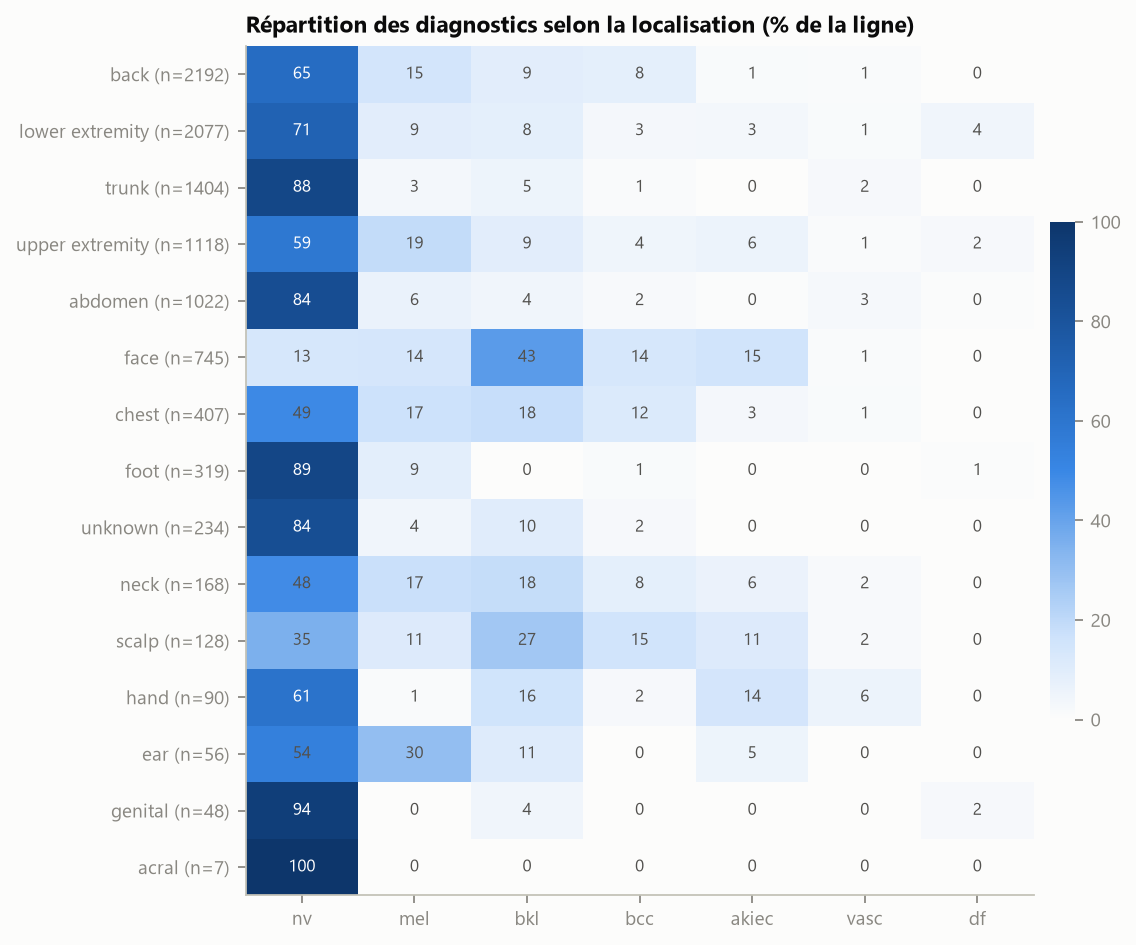

,variable,V de Cramér,p (χ²)
0,sex,0.073,2.4e-17
1,localization,0.217,0.0e+00
2,dx_type,0.390,0.0e+00
3,age (5 tranches),0.248,0.0e+00


dx_type,confocal,consensus,follow_up,histo
dx,,,,
nv,0,503,3704,2498
mel,0,0,0,1113
bkl,69,264,0,766
bcc,0,0,0,514
akiec,0,0,0,327
vasc,0,75,0,67
df,0,60,0,55


In [4]:
print("Âge :", eda["age_stats"], "| âges = 0 :", eda["age_zero"], "| part des âges multiples de 5 :", eda["age_multiple_5"])
fig("02_age_par_classe", 750); fig("02_sexe", 750); fig("02_localisation", 800)
display(eda["association"])
display(eda["dx_type"])

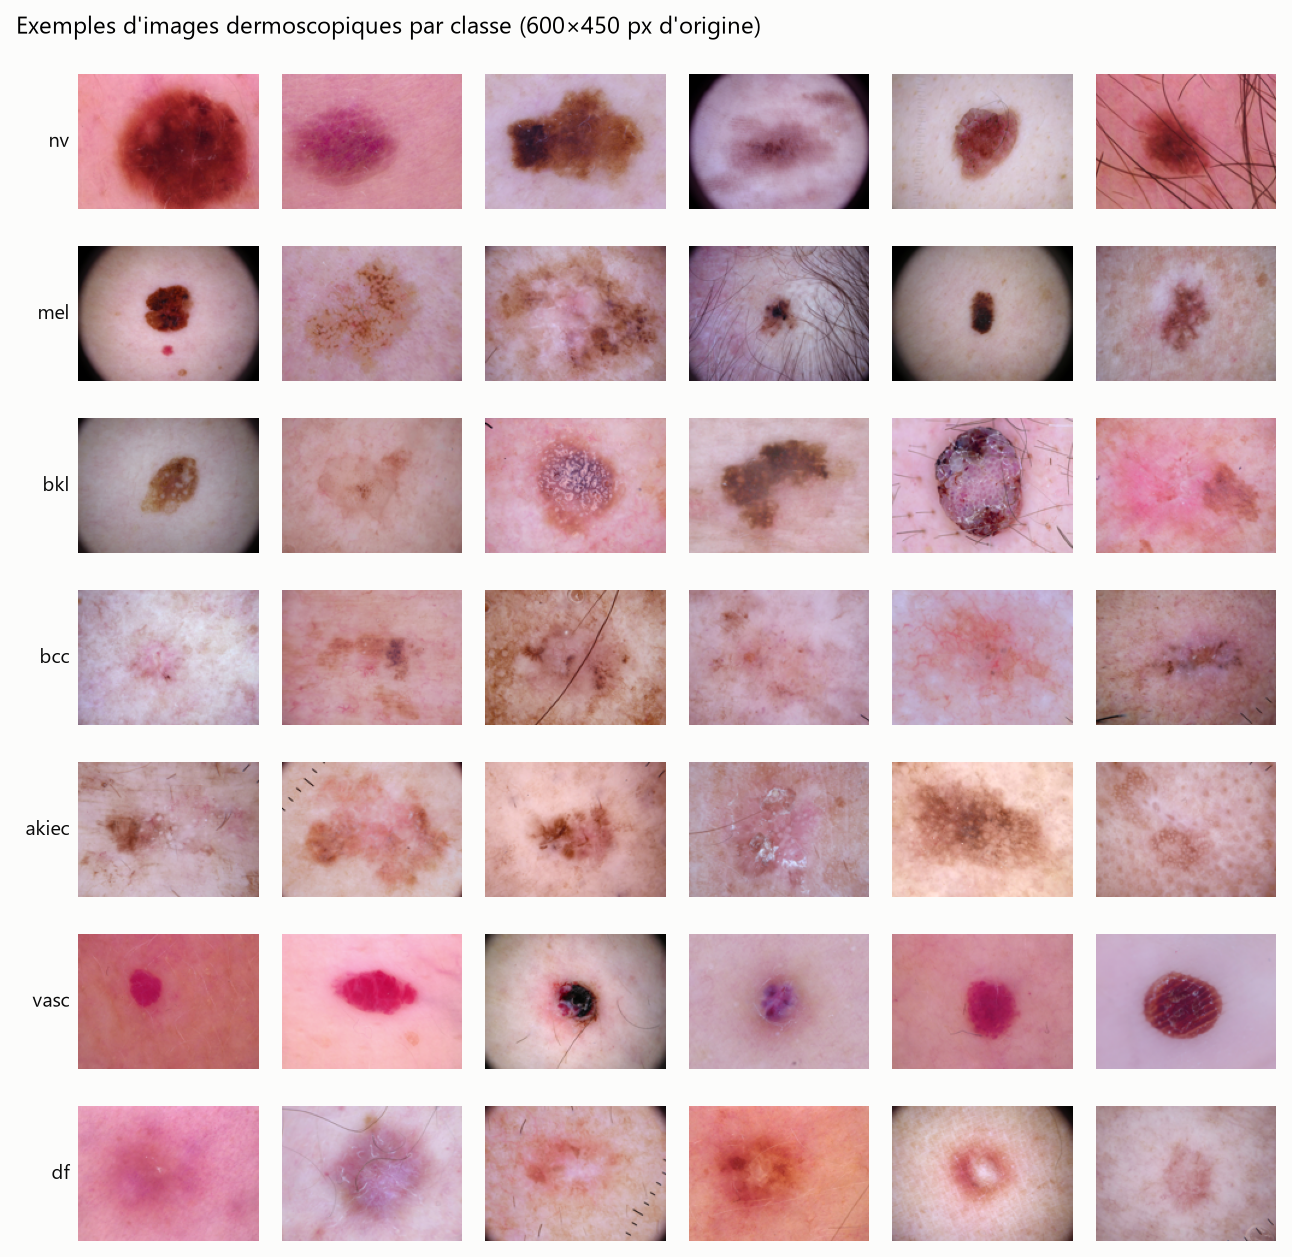

In [5]:
fig("02_exemples_images", 850)

**Ce qu'il faut retenir de l'exploration**

- **Structure.** 10 015 images, 7 470 lésions, aucune image manquante sur le disque, aucune lésion avec deux
  diagnostics. **26 % des lésions ont plusieurs images** (jusqu'à 6). Les mélanomes ont 1,81 image par lésion contre
  1,24 pour les nævus : un découpage *par image* ferait fuir surtout… les mélanomes.
- **Déséquilibre.** nv 66,9 % ; mel 11,1 % ; df 1,1 % (rapport 58 : 1 entre la plus grande et la plus petite classe).
- **Âge.** 57 manquants (0,6 %) ; 39 âges égaux à 0 (nævus, kératoses et lésions vasculaires : nævus congénitaux,
  hémangiomes du nourrisson — plausibles, conservés) ; **100 % des âges sont des multiples de 5** (arrondi
  d'anonymisation). Mélanomes, carcinomes et kératoses touchent des patients plus âgés (médianes 60–70 ans) que les
  nævus (45 ans).
- **Force d'association avec le diagnostic (V de Cramér)** : sexe 0,07 (très faible), localisation 0,22, âge 0,25.
  **Le contexte est informatif mais faible** comparé à l'image.
- **Localisation.** Le visage est dominé par les kératoses bénignes (43 %), actiniques (15 %) et les carcinomes
  (14 %) — zones exposées au soleil ; 71 % des dermatofibromes siègent sur le membre inférieur. **« trunk » contient 88 % de
  nævus alors que « back », « chest » et « abdomen » existent aussi** : le codage de la localisation diffère
  probablement selon les centres (biais à garder en tête).
- **Fuite par `dx_type`** (V = 0,39) : `follow_up` n'existe que pour des nævus (3 704 images) et tous les mélanomes
  sont `histo`. Utiliser cette colonne donnerait des résultats artificiellement bons : **exclue des entrées**.
- **Images.** 600×450 px ; variations de couleur et d'éclairage, cercles noirs du dermoscope, poils, règles graduées :
  autant d'artefacts que le réseau pourrait exploiter à tort.

## Étape 3 — Prétraitement

- **Découpage par lésion** (`lesion_id`), stratifié sur le diagnostic : **70 % train, 10 % validation, 10 %
  calibration, 10 % test**, graine 42. Validation = arrêt de l'entraînement et réglage des seuils ; calibration =
  prédiction conforme uniquement ; test = évaluation finale, jamais utilisé pour régler quoi que ce soit.
- **Tabulaire** (ajusté sur le train seulement) : âge imputé par la médiane + indicateur « âge manquant », puis
  standardisé ; sexe et localisation en one-hot avec une catégorie « unknown » → **20 variables**.
- **Images** : redimensionnées une fois en 224×224 (cache `.npy` de 1,5 Go, dérivé et régénérable), normalisation
  ImageNet ; **augmentation sur le train seulement**, en lot sur GPU : retournements, rotation quelconque, zoom
  (×1–1,25), translation (±6 %), luminosité / contraste / saturation (±15 %).
- **3 graines d'entraînement** (0, 1, 2) sur le même découpage ; la variabilité due à l'échantillon de test est
  mesurée par bootstrap (étape 7).

In [6]:
from src import prepare
prepare.main()        # découpage par lésion + contrôles anti-fuite + encodeur clinique + cache d'images

      images                   lésions                
split  train   val calib  test   train  val calib test
dx                                                    
nv      4683   675   673   674    3782  540   540  541
mel      773   117   110   113     430   61    61   62
bkl      772   108   108   111     509   73    73   72
bcc      361    54    51    48     229   33    33   32
akiec    222    38    34    33     159   23    23   23
vasc      99    17    13    13      69   10    10    9
df        71    14    13    17      51    7     7    8
total   6981  1023  1002  1009    5229  747   747  747

Fraction des lésions : {'train': 0.7, 'val': 0.1, 'calib': 0.1, 'test': 0.1}
Fraction des images  : {'train': 0.697, 'val': 0.102, 'calib': 0.1, 'test': 0.101}

Proportion de classes par jeu (%) :
 split  train   val  calib  test
dx                             
nv      67.1  66.0   67.2  66.8
mel     11.1  11.4   11.0  11.2
bkl     11.1  10.6   10.8  11.0
bcc      5.2   5.3    5.1   4.8
akie

OK : découpage, encodage et cache vérifiés.


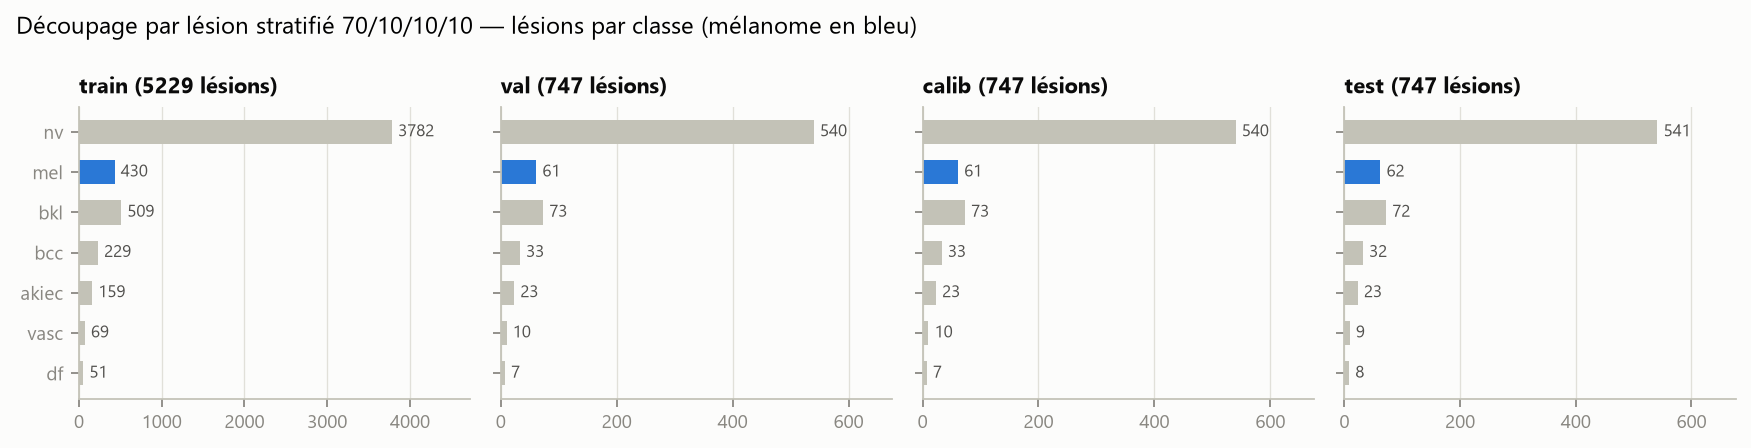

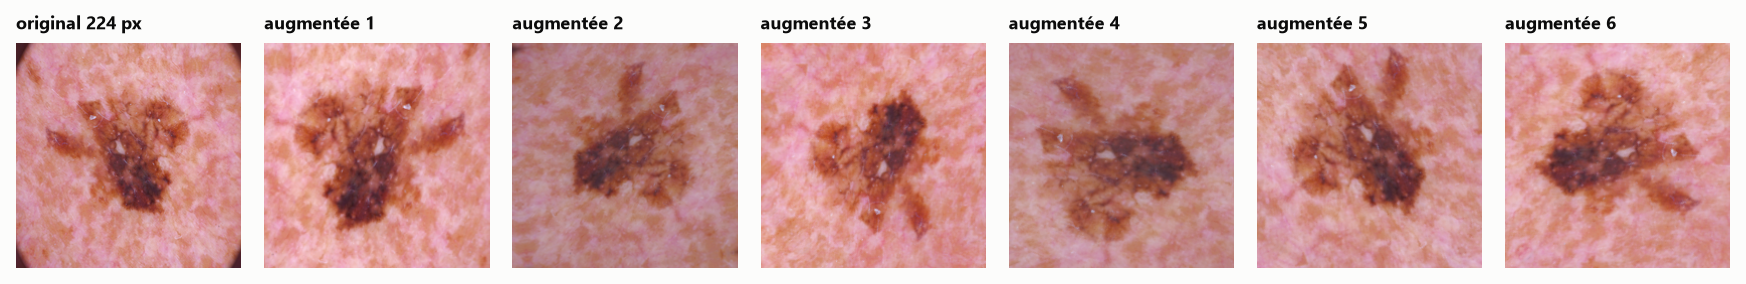

In [7]:
fig("03_decoupage"); fig("03_augmentations")

**Vérifications** : aucune lésion n'apparaît dans deux jeux (assertion dans le code) ; proportions de classes
quasi identiques entre jeux (écart maximal < 3 points, assertion) ; âge normalisé sur le train (moyenne 0, écart-type 1).
Le **test contient 1 009 images (747 lésions) dont 113 images de mélanome (62 lésions)**, mais seulement
17 images de dermatofibrome (8 lésions) et 13 de lésions vasculaires (9 lésions) : les résultats sur ces deux
classes rares sont très incertains.

## Étape 4 — Baseline M1 : image seule

EfficientNet-B0 pré-entraîné sur ImageNet [Tan & Le 2019] (4,0 M paramètres), tête `Dropout(0,3) → Linéaire(7)`.
Entraînement commun à **tous** les réseaux (seules la fusion et la perte changent) : AdamW (lr 3·10⁻⁴ pour le tronc,
10⁻³ pour les couches nouvelles, décroissance 0,01), lots de 32, cosinus avec une époque de chauffe, précision mixte,
**15 époques au plus, meilleure époque et arrêt (patience 5) selon le F1 macro de validation**. Prédictions finales
avec 4 retournements (TTA). Durée : **≈ 7 min par entraînement sur la RTX 3050 (4 Go)**, 19 entraînements, 2 h 17 au
total. Deux réglages ont été mesurés avant de lancer : le format mémoire `channels_last` était 7× plus lent sur ce
GPU, et l'auto-réglage cuDNN coûtait ~90 s par forme de lot ; tous deux sont désactivés.

none   : 4.02 M paramètres
concat : 4.02 M paramètres
film   : 4.25 M paramètres


,exp,seed,best_val_f1,best_epoch,epochs_run,train_time_s
0,M1,0,0.651068,8,13,368.2
1,M1,1,0.664340,8,13,372.3
2,M1,2,0.627495,14,15,422.7
3,M3,0,0.675079,10,15,428.8
4,M3,1,0.639484,15,15,426.1
5,M3,2,0.663424,15,15,428.0
6,M5,0,0.698405,8,13,378.9
7,M5,1,0.663817,11,15,436.1
8,M5,2,0.670655,11,15,436.0
9,M5_filmMulti,0,0.661633,15,15,443.8


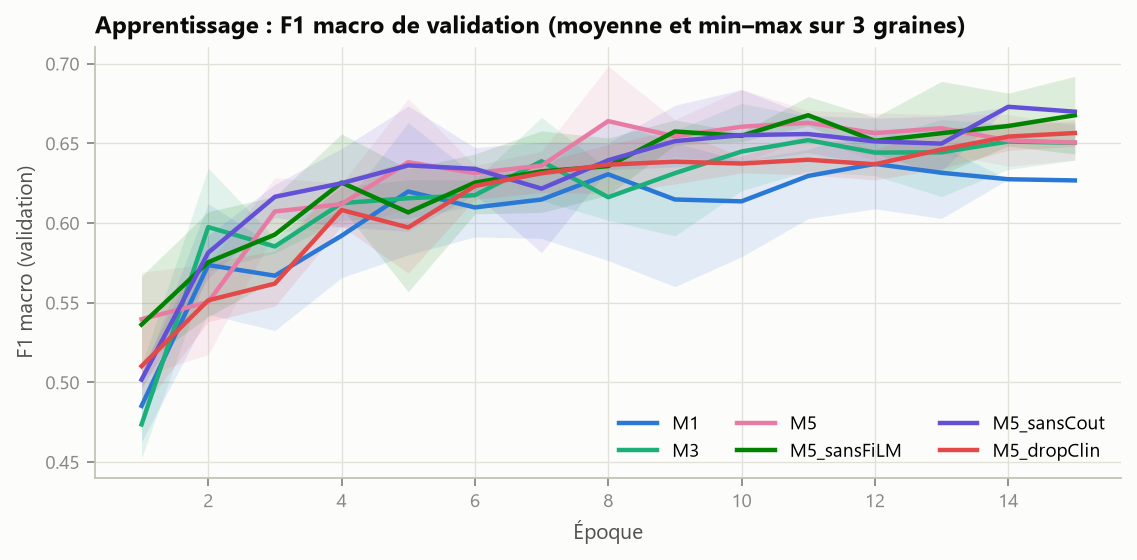

In [8]:
from src.models import SkinNet
for fusion in ["none", "concat", "film"]:
    m = SkinNet(fusion=fusion, pretrained=False)
    n = sum(p.numel() for p in m.parameters())
    print(f"{fusion:7s}: {n/1e6:.2f} M paramètres")

if RUN_TRAINING:
    subprocess.run([sys.executable, "-m", "src.run_all"], check=True)
display(tab("04_entrainements"))
fig("04_courbes_apprentissage", 750)

## Étape 5 — Second modèle M2 : contexte clinique seul

XGBoost [Chen & Guestrin 2016] sur les 20 variables cliniques, comparé à une forêt aléatoire. Hyperparamètres **et
nombre d'arbres** choisis par **validation croisée à 5 plis sur le train, groupée par lésion**, sur la log-loss : la
validation reste intacte pour choisir ensuite, sans biais, le poids de la fusion tardive M4. Retenu : XGBoost,
profondeur 2, 400 arbres (log-loss CV 0,905). Sur la validation : log-loss **0,960** contre **1,166** pour une
prédiction constante égale aux fréquences des classes — le contexte apporte de l'information, mais peu.
Sur le test (tableau de l'étape 7) : **F1 macro 0,165, AUC mélanome 0,707** ; en décision classique, M2 prédit
presque toujours « nævus » (sensibilité mélanome 0,035). Seul, le contexte est inutilisable cliniquement.

In [9]:
display(tab("05_M2_grille_validation_croisee").head(8))
display(tab("05_M2_importances_RF").head(8))

,modèle,params,log-loss CV,F1 macro CV
0,XGBoost,"{""max_depth"": 2, ""min_child_weight"": 1, ""n_estimators"": ...",0.9051,0.1849
1,XGBoost,"{""max_depth"": 2, ""min_child_weight"": 5, ""n_estimators"": ...",0.9069,0.1855
2,XGBoost,"{""max_depth"": 3, ""min_child_weight"": 1, ""n_estimators"": ...",0.9069,0.1809
3,XGBoost,"{""max_depth"": 3, ""min_child_weight"": 5, ""n_estimators"": ...",0.9078,0.1852
4,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 5, ""n_estimators"": ...",0.9082,0.1850
5,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 1, ""n_estimators"": ...",0.9085,0.1848
6,XGBoost,"{""max_depth"": 6, ""min_child_weight"": 5, ""n_estimators"": ...",0.9103,0.1874
7,XGBoost,"{""max_depth"": 4, ""min_child_weight"": 20, ""n_estimators"":...",0.9106,0.1928


,Unnamed: 0,importance (impureté)
0,age,0.5612
1,loc=face,0.2291
2,loc=trunk,0.0621
3,loc=abdomen,0.0365
4,loc=chest,0.0176
5,loc=upper extremity,0.0157
6,loc=back,0.0136
7,loc=lower extremity,0.0127


## Étape 6 — Approches multimodales : M3, M4 et le modèle proposé M5

- **M3 — fusion précoce** : `[h_image (1 280) ; MLP(contexte) (64)] → tête`. Le contexte ajoute un terme *additif*
  aux scores.
- **M4 — fusion tardive** : `p = w·p_M1 + (1−w)·p_M2`, w choisi sur la validation (grille 0 → 1 par 0,05).
- **M5 — fusion guidée par le patient (proposé)** : un MLP clinique produit, pour chacun des 1 280 canaux de l'image,
  un gain γ et un décalage β : `h ← (1 + γ) ⊙ h + β` (FiLM [Perez 2018]). Le contexte change **la façon de lire
  l'image** (interaction multiplicative), pas seulement le score final. Générateurs initialisés à zéro : au départ,
  M5 est exactement le CNN pré-entraîné. S'y ajoutent une **perte pondérée** (poids ∝ (n_max/n_k)^0,5, ×2 pour le
  mélanome) et un **seuil de décision au coût** (étape 8).
- **Choix de la variante FiLM sur la validation** (graine 0, règle fixée avant : meilleur F1 macro de validation) :
  FiLM sur les seuls canaux finaux **0,698** contre **0,662** pour FiLM sur trois étages (192, 320, 1 280 canaux).
  La variante la plus simple est retenue.
- **Positionnement honnête.** Moduler l'image par les métadonnées n'est pas nouveau en dermatologie : MetaNet
  [Li 2020] et MetaBlock [Pacheco & Krohling 2021] le font déjà. L'originalité de ce travail est **l'assemblage
  orienté sécurité** — modulation FiLM + décision au coût + abstention conforme conditionnelle au mélanome — et son
  évaluation rigoureuse (ablations, 3 graines, bootstrap par lésion).

Poids de l'image dans M4 : {'0': 0.9, '1': 0.75, '2': 0.95}


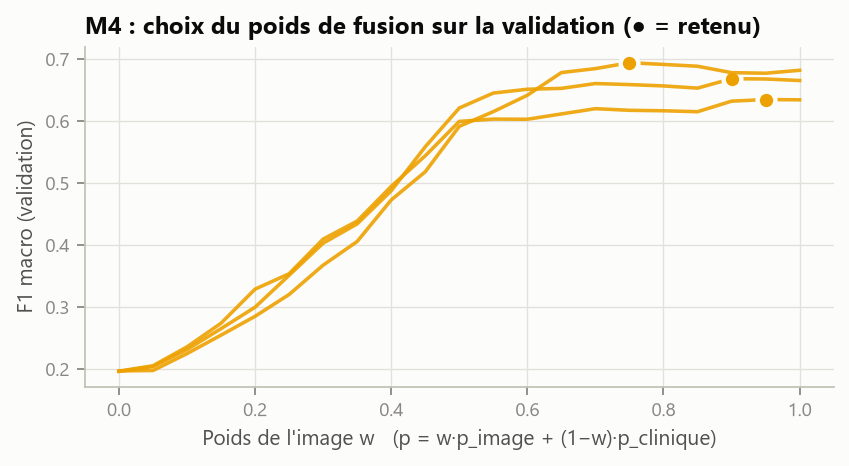

In [10]:
from src import results
quiet(results.main)                # étapes 4 à 8 : décisions, métriques, bootstrap, figures (≈ 30 s)
print("Poids de l'image dans M4 :", json.loads((C.TAB_DIR / "06_M4_poids.json").read_text()))
fig("06_M4_poids", 600)

## Étape 7 — Comparer unimodal et multimodal

Même découpage pour tous, 3 graines, **moyenne ± écart-type** sur le test. Chaque modèle est évalué avec **deux
règles de décision** : *classique* (classe la plus probable) et *au coût* (seuil sur p(mélanome) réglé sur la
validation, R = 10). Sans cela, un gain de M5 pourrait venir du seul seuil et non du modèle. Les comparaisons clés
ont un **IC 95 % par bootstrap apparié** : 2 000 rééchantillonnages **des lésions** du test (les images d'une même
lésion sont corrélées), métrique moyennée sur les 3 graines dans chaque rééchantillon.

,modèle,décision,F1 macro,Exactitude équilibrée,AUC OvR macro,AUC mel,Sensibilité mel,Spécificité mel,Coût attendu,Exactitude,n graines
0,M1 image,classique,0.646 ± 0.023,0.622 ± 0.017,0.956 ± 0.003,0.909 ± 0.008,0.593 ± 0.062,0.940 ± 0.013,0.595 ± 0.069,0.815 ± 0.016,3
1,M1 image,coût R=10,0.590 ± 0.036,0.571 ± 0.029,0.956 ± 0.003,0.909 ± 0.008,0.811 ± 0.022,0.815 ± 0.012,0.436 ± 0.028,0.754 ± 0.008,3
2,M2 clinique,classique,0.165 ± 0.002,0.178 ± 0.002,0.806 ± 0.002,0.707 ± 0.001,0.035 ± 0.000,0.992 ± 0.000,1.287 ± 0.002,0.685 ± 0.002,3
3,M2 clinique,coût R=10,0.147 ± 0.005,0.207 ± 0.005,0.806 ± 0.002,0.707 ± 0.001,0.817 ± 0.005,0.530 ± 0.035,0.670 ± 0.020,0.514 ± 0.025,3
4,M3 concaténation,classique,0.685 ± 0.006,0.651 ± 0.010,0.962 ± 0.002,0.913 ± 0.004,0.599 ± 0.036,0.944 ± 0.008,0.573 ± 0.040,0.832 ± 0.006,3
5,M3 concaténation,coût R=10,0.617 ± 0.022,0.588 ± 0.025,0.962 ± 0.002,0.913 ± 0.004,0.826 ± 0.052,0.814 ± 0.058,0.411 ± 0.024,0.765 ± 0.036,3
6,M4 fusion tardive,classique,0.640 ± 0.022,0.611 ± 0.020,0.950 ± 0.007,0.905 ± 0.013,0.578 ± 0.080,0.943 ± 0.016,0.609 ± 0.087,0.816 ± 0.014,3
7,M4 fusion tardive,coût R=10,0.600 ± 0.012,0.576 ± 0.011,0.950 ± 0.007,0.905 ± 0.013,0.779 ± 0.072,0.840 ± 0.049,0.456 ± 0.053,0.767 ± 0.023,3
8,M5 FiLM + coût (proposé),classique,0.674 ± 0.016,0.673 ± 0.012,0.963 ± 0.003,0.920 ± 0.007,0.673 ± 0.015,0.911 ± 0.004,0.527 ± 0.027,0.803 ± 0.013,3
9,M5 FiLM + coût (proposé),coût R=10,0.609 ± 0.065,0.605 ± 0.044,0.963 ± 0.003,0.920 ± 0.007,0.882 ± 0.090,0.775 ± 0.082,0.389 ± 0.037,0.730 ± 0.056,3


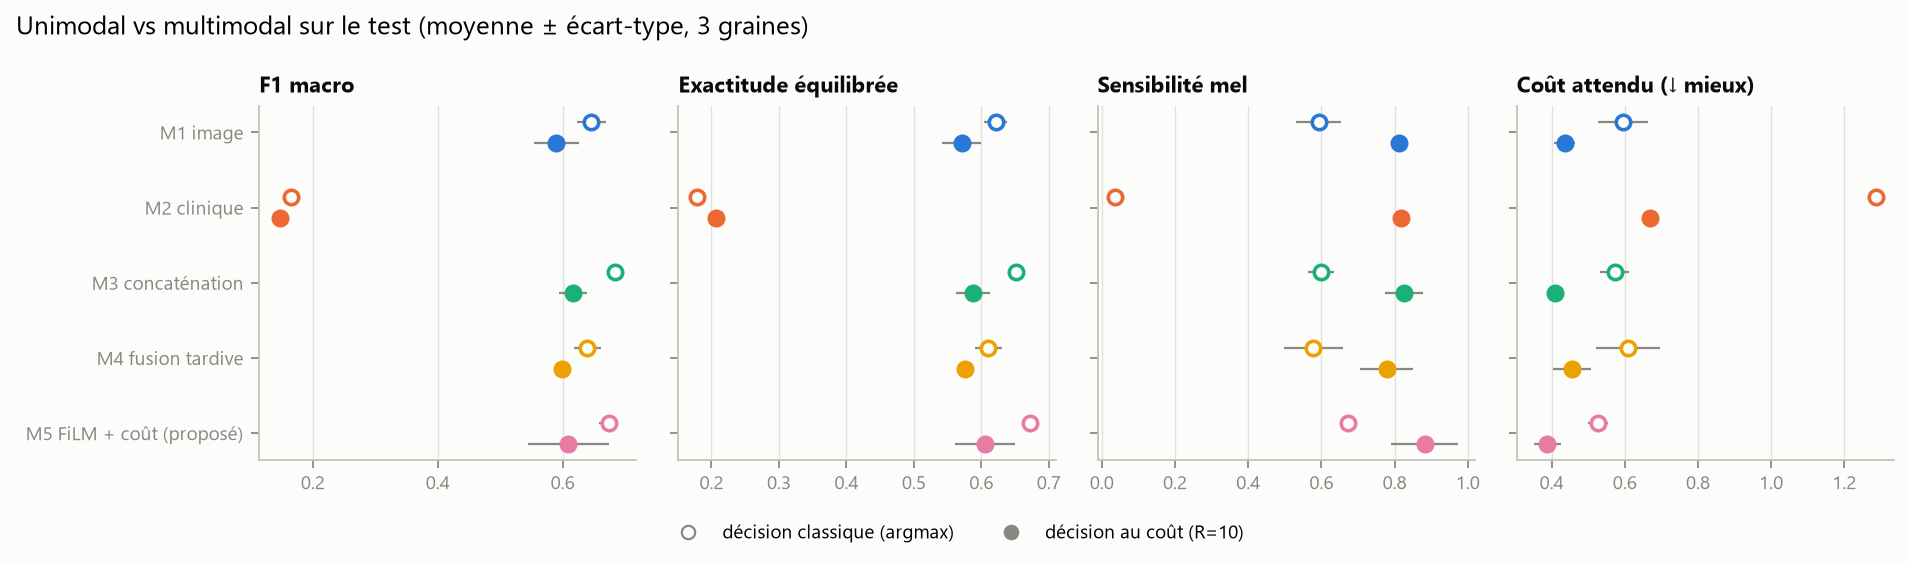

In [11]:
final = tab("07_comparaison_finale")
display(final)
fig("07_comparaison_modeles")

In [12]:
display(tab("07_bootstrap_comparaisons"))

,comparaison,métrique,A,B,différence,IC95 %,significatif,P(A meilleur)
0,M5 [coût R=10] − M1 [classique],F1 macro,0.6092,0.6462,-0.0370,[-0.071 ; -0.004],True,0.014
1,M5 [coût R=10] − M1 [classique],Exactitude équilibrée,0.6053,0.6215,-0.0162,[-0.049 ; +0.015],False,0.171
2,M5 [coût R=10] − M1 [classique],Sensibilité mel,0.8820,0.5929,0.2891,[+0.221 ; +0.366],True,1.000
3,M5 [coût R=10] − M1 [classique],Coût attendu,0.3888,0.5950,-0.2061,[-0.330 ; -0.106],True,1.000
4,M5 [coût R=10] − M1 [classique],AUC mel,0.9198,0.9088,0.0110,[-0.006 ; +0.029],False,0.886
5,M5 [coût R=10] − M1 [coût R=10],F1 macro,0.6092,0.5897,0.0196,[-0.010 ; +0.053],False,0.900
6,M5 [coût R=10] − M1 [coût R=10],Exactitude équilibrée,0.6053,0.5712,0.0341,[+0.009 ; +0.061],True,0.997
7,M5 [coût R=10] − M1 [coût R=10],Sensibilité mel,0.8820,0.8112,0.0708,[+0.010 ; +0.137],True,0.989
8,M5 [coût R=10] − M1 [coût R=10],Coût attendu,0.3888,0.4364,-0.0476,[-0.125 ; +0.023],False,0.910
9,M5 [coût R=10] − M1 [coût R=10],AUC mel,0.9198,0.9088,0.0110,[-0.006 ; +0.029],False,0.886


**Lecture des résultats (test, moyenne de 3 graines)**

1. **Image ≫ contexte.** M1 : F1 macro 0,646, AUC 0,956 ; M2 : F1 0,165. L'image porte l'essentiel de l'information.
2. **Le contexte aide un peu, à condition de bien le fusionner.** M3 (concaténation) dépasse M1 en F1 macro :
   **+0,038 [IC 95 % +0,005 ; +0,074]**. La fusion tardive M4 n'apporte rien (exactitude équilibrée −0,011,
   significatif) : le poids appris donne 75–95 % à l'image.
3. **M5 en décision classique** dépasse M1 en exactitude équilibrée (**+0,051 [+0,023 ; +0,084]**) et en sensibilité
   mélanome (**+0,080 [+0,025 ; +0,140]**), avec un coût attendu plus bas (−0,068 [−0,140 ; −0,005]).
4. **Le seuil de coût est le levier principal de sécurité.** Appliqué à M1 seul, il fait passer la sensibilité
   mélanome de 0,593 à 0,811. L'IA prudente complète (M5 au coût) atteint **0,882** et réduit le coût attendu de
   **0,595 à 0,389** par rapport au classifieur classique (M1, argmax) : **−0,206 [−0,330 ; −0,106]**.
   **Prix à payer** : F1 macro plus bas (−0,037 [−0,071 ; −0,004]) et spécificité mélanome 0,775 au lieu de 0,940.
5. **À règle de décision égale** (tous au coût), M5 bat M1 en sensibilité (+0,071 [+0,010 ; +0,137]) et en exactitude
   équilibrée (+0,034 [+0,009 ; +0,061]), M3 en sensibilité (+0,056 [+0,022 ; +0,096]), M4 en sensibilité et en coût.
   **Mais l'AUC mélanome — qui ne dépend d'aucun seuil — ne diffère significativement entre aucun modèle**
   (M5 0,920 contre 0,909 pour M1, [−0,006 ; +0,029]) : une partie du gain de sensibilité vient d'un point de
   fonctionnement plus « alarmiste » (spécificité plus basse), pas d'une meilleure discrimination.

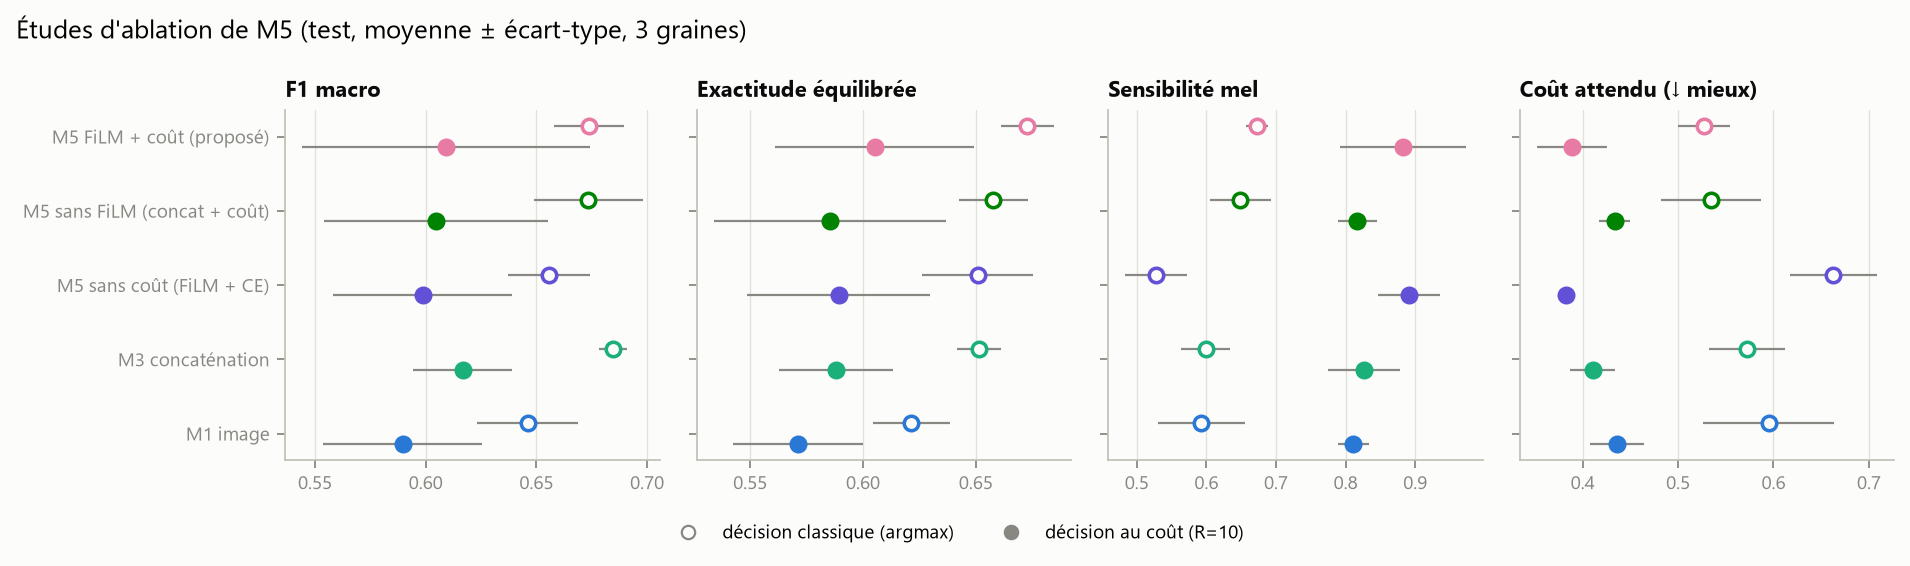

In [13]:
fig("07_ablations")

**Études d'ablation (toutes au coût, R = 10)**

| Ablation | Résultat | Conclusion |
|---|---|---|
| M5 **sans FiLM** (concaténation + même perte) | M5 − ablation : sensibilité mel **+0,065 [+0,030 ; +0,102]**, coût **−0,045 [−0,094 ; −0,002]** ; F1 (+0,005) et AUC mel (+0,012 [−0,001 ; +0,028]) non significatifs | **FiLM apporte un gain modeste mais réel** sur la sécurité ; pas sur le F1 |
| Réplication : FiLM − concaténation, **tous deux avec la perte classique** | sensibilité mel **+0,065 [+0,026 ; +0,112]** ; coût −0,028 [−0,091 ; +0,018] (n.s.) | même direction : **effet du FiLM reproduit** |
| M5 **sans perte de coût** (FiLM + entropie croisée) | M5 − ablation : aucune différence significative (sensibilité −0,009 [−0,037 ; +0,020], coût +0,007) | **la perte pondérée est redondante** avec le seuil de coût réglé sur la validation |
| M5 **sans abstention** | voir étape 8 : 37 mélanomes manqués (argmax) ou ~13 (coût) sans abstention contre 6,7 avec | **l'abstention est l'ingrédient de sécurité le plus fort** |

## Étape 8 — Évaluer : métriques adaptées, coût, abstention

- **Métriques** : F1 macro, exactitude équilibrée, AUC un-contre-tous, sensibilité / spécificité mélanome, matrices de
  confusion, **coût attendu** (mélanome manqué = R, toute autre erreur = 1, correct = 0), couverture et abstention.
  L'exactitude seule est trompeuse : répondre toujours « nævus » donne 67 %.
- **Sensibilité au rapport de coût** : R = 5, 10, 20 (le seuil est re-réglé sur la validation pour chaque R ; pas de
  réentraînement).
- **Prédiction conforme** [Vovk 2005 ; Angelopoulos & Bates 2021] calibrée sur le jeu de calibration, α = 0,1. Trois
  scores : LAC [Sadinle 2019], APS randomisé [Romano 2020] et **LAC conditionnel par classe (Mondrian)**.
  **Règle de choix fixée avant de regarder le test** : parmi les méthodes qui couvrent le mélanome à ≥ 90 % *sur la
  validation*, prendre celle qui traite le plus de cas. **L'IA décide seule** si l'ensemble conforme est un singleton
  qui coïncide avec la décision au coût ; **sinon elle renvoie au médecin**.

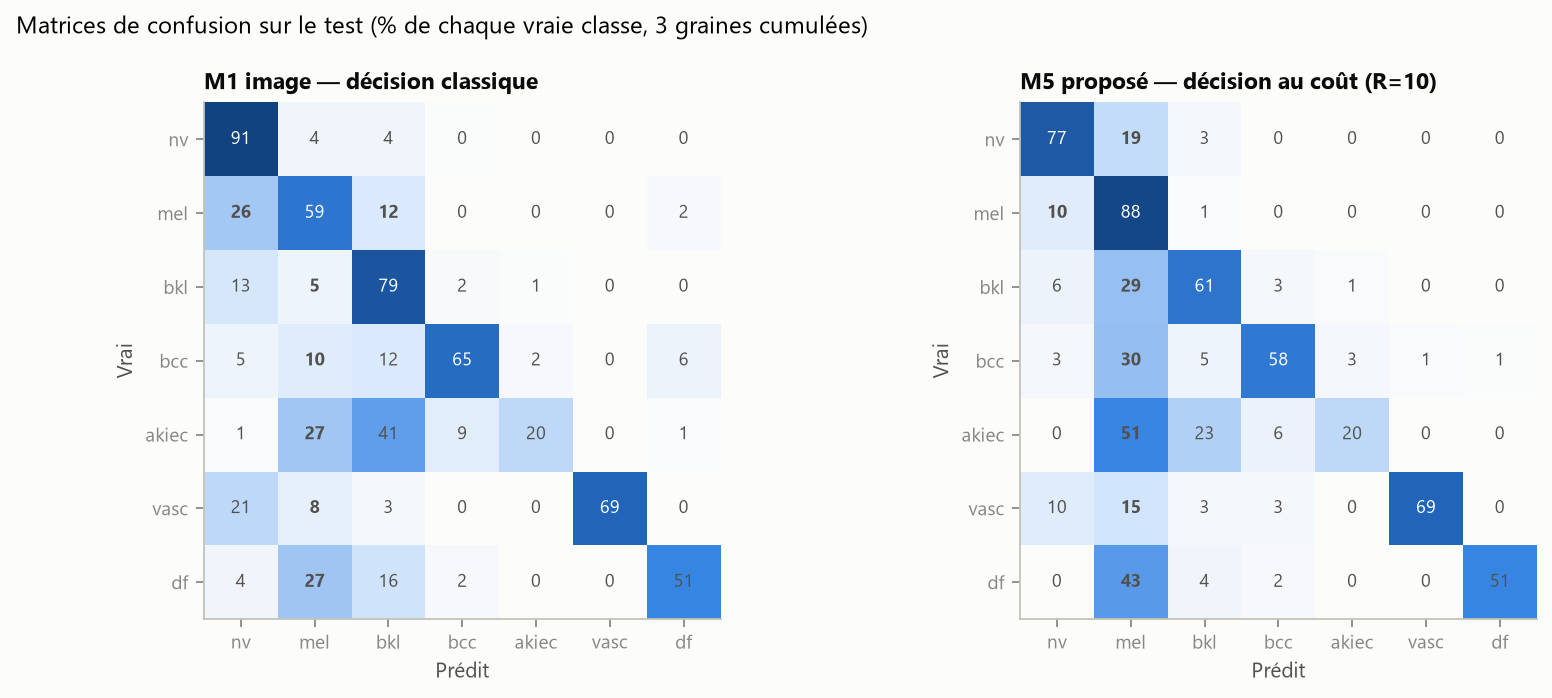

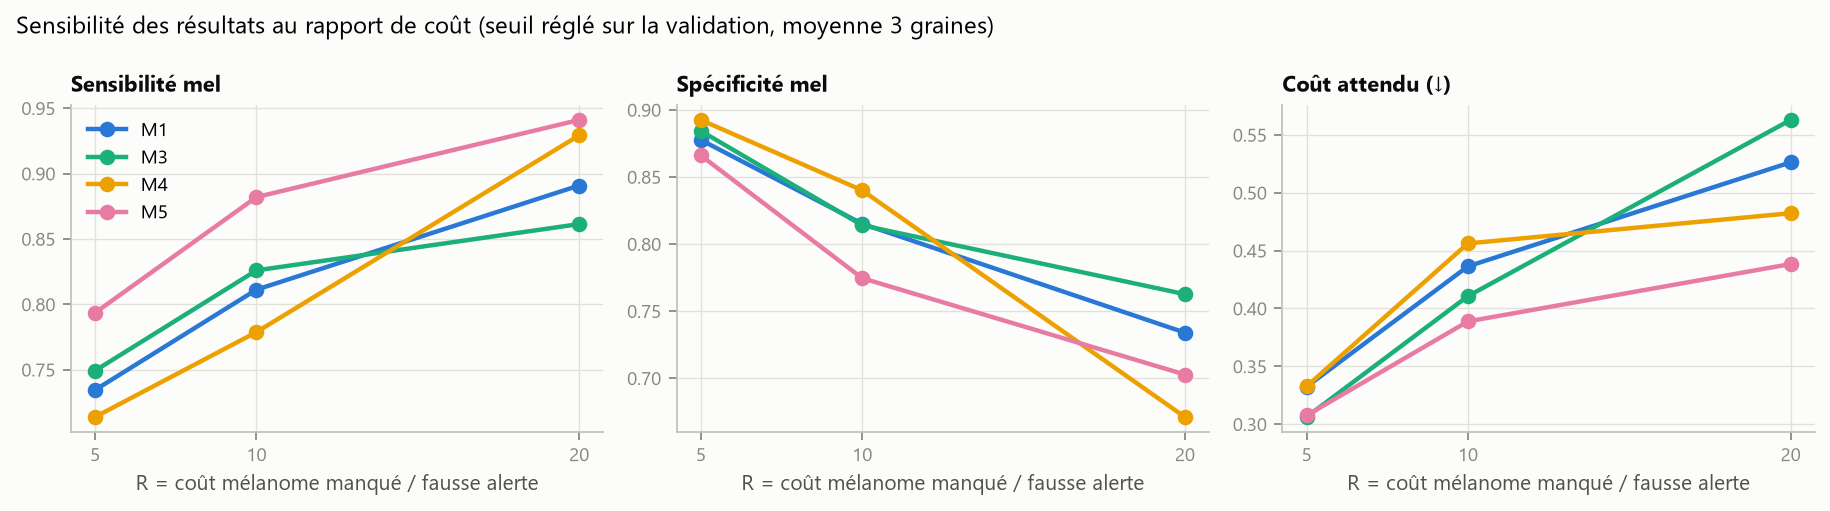

seuil        Sensibilité mel        Spécificité mel        Coût attendu        Coût attendu (argmax)        F1 macro       
            mean    std            mean    std            mean    std         mean    std                  mean    std     mean    std
modèle R                                                                                                                              
M1     5   0.223  0.101           0.735  0.039           0.878  0.033        0.332  0.010                 0.367  0.036    0.620  0.038
       10  0.090  0.061           0.811  0.022           0.815  0.012        0.436  0.028                 0.595  0.069    0.590  0.036
       20  0.033  0.025           0.891  0.067           0.734  0.063        0.526  0.111                 1.051  0.137    0.550  0.018
M3     5   0.147  0.038           0.749  0.049           0.884  0.022        0.306  0.010                 0.348  0.020    0.658  0.026
       10  0.063  0.059           0.826  0.052           0.814  0.058        0.411  0.024                 0.573  0.040    0.617  0.022
       20  0.023  0.015           0.861  0.065           0.763  0.065        0.563  0.098                 1.022  0.080    0.591  0.040
M4     5   0.237  0.076           0.714  0.034           0.892  0.023        0.333  0.011                 0.373  0.043    0.624  0.037
       10  0.123  0.064           0.779  0.072           0.840  0.049        0.456  0.053                 0.609  0.087    0.600  0.012
       20  0.033  0.012           0.929  0.009           0.671  0.069        0.482  0.035                 1.082  0.176    0.511  0.081
M5     5   0.243  0.015           0.794  0.028           0.866  0.012        0.308  0.005                 0.344  0.019    0.663  0.016
       10  0.100  0.104           0.882  0.090           0.775  0.082        0.389  0.037                 0.527  0.027    0.609  0.065
       20  0.027  0.015           0.941  0.018           0.703  0.019        0.438  0.032                 0.894  0.044    0.565  0.021

In [14]:
fig("08_matrices_confusion")
fig("08_sensibilite_cout")
display(tab("08_sensibilite_cout", header=[0, 1], index_col=[0, 1]).round(3))

In [15]:
print("Choix de la méthode conforme (calibration → mesuré sur la VALIDATION) :")
display(tab("08_choix_conforme_validation", index_col=0))
print("Méthode retenue :", json.loads((C.TAB_DIR / "08_methode_conforme.json").read_text()))
display(tab("08_abstention_resume", index_col=0).T)

Choix de la méthode conforme (calibration → mesuré sur la VALIDATION) :


,couverture,taille moyenne,singletons,vides,couverture mel,taux traité,mel manqués en silence (val)
méthode,,,,,,,
aps,0.884,1.362,0.673,0.029,0.877,0.636,7.333
lac,0.880,1.192,0.818,0.000,0.846,0.746,8.667
mondrian,0.884,1.469,0.673,0.000,0.937,0.670,5.000


Méthode retenue : {'méthode': 'mondrian', 'alpha': 0.1}


modèle,M1 image,M2 clinique,M3 concaténation,M4 fusion tardive,M5 FiLM + coût (proposé),M5 sans FiLM (concat + coût),M5 sans coût (FiLM + CE),M5 + dropout clinique (bonus)
couverture conforme,0.874 ± 0.012,0.926 ± 0.005,0.88 ± 0.008,0.875 ± 0.011,0.889 ± 0.004,0.883 ± 0.011,0.896 ± 0.005,0.883 ± 0.009
couverture conforme mel,0.861 ± 0.034,0.912 ± 0.031,0.879 ± 0.027,0.87 ± 0.042,0.923 ± 0.01,0.858 ± 0.047,0.92 ± 0.009,0.894 ± 0.041
taille moyenne ensemble,1.393 ± 0.076,4.274 ± 0.025,1.402 ± 0.029,1.421 ± 0.125,1.47 ± 0.048,1.5 ± 0.097,1.473 ± 0.078,1.401 ± 0.058
taux traité,0.704 ± 0.039,0.012 ± 0.002,0.708 ± 0.013,0.679 ± 0.069,0.655 ± 0.011,0.664 ± 0.052,0.654 ± 0.033,0.694 ± 0.017
taux d'abstention,0.296 ± 0.039,0.988 ± 0.002,0.292 ± 0.013,0.321 ± 0.069,0.345 ± 0.011,0.336 ± 0.052,0.346 ± 0.033,0.306 ± 0.017
F1 macro (traités),0.746 ± 0.041,0.477 ± 0.005,0.806 ± 0.004,0.73 ± 0.062,0.819 ± 0.03,0.82 ± 0.03,0.824 ± 0.06,0.781 ± 0.04
Exactitude (traités),0.896 ± 0.016,0.912 ± 0.02,0.906 ± 0.009,0.895 ± 0.014,0.901 ± 0.006,0.915 ± 0.014,0.916 ± 0.011,0.898 ± 0.01
Sensibilité mel (traités),0.777 ± 0.019,NaN,0.823 ± 0.036,0.803 ± 0.018,0.88 ± 0.028,0.781 ± 0.052,0.846 ± 0.051,0.831 ± 0.066
"Sensibilité mel (tous, sans abstention)",0.811 ± 0.022,0.817 ± 0.005,0.826 ± 0.052,0.779 ± 0.072,0.882 ± 0.09,0.817 ± 0.028,0.891 ± 0.045,0.829 ± 0.034
"Sensibilité mel (tous, argmax)",0.593 ± 0.062,0.035 ± 0.0,0.599 ± 0.036,0.578 ± 0.08,0.673 ± 0.015,0.649 ± 0.044,0.528 ± 0.045,0.622 ± 0.062


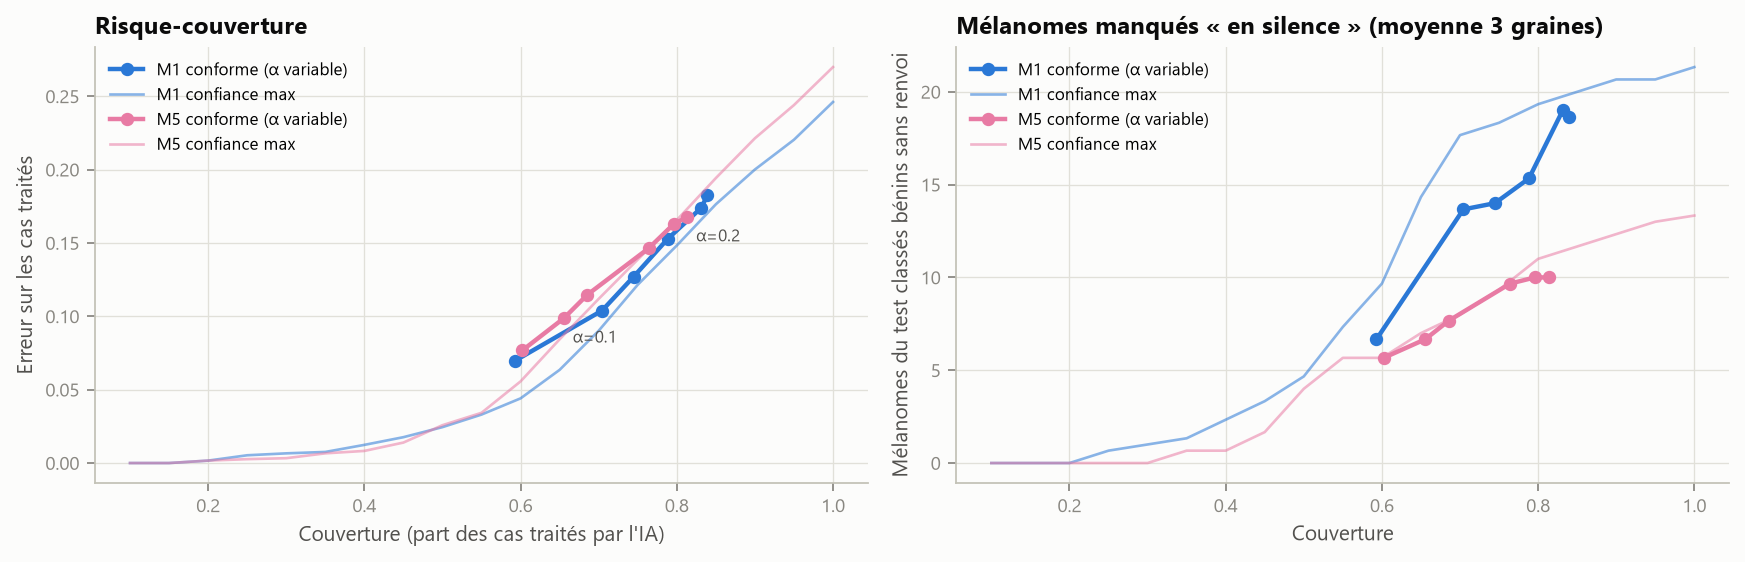

méthode,lac,aps,mondrian
couverture conforme,0.878,0.885,0.889
couverture conforme mel,0.820,0.864,0.923
taille moyenne ensemble,1.201,1.374,1.470
taux traité,0.745,0.642,0.655
taux d'abstention,0.255,0.358,0.345
F1 macro (traités),0.776,0.813,0.819
Exactitude (traités),0.891,0.919,0.901
Sensibilité mel (traités),0.841,0.840,0.880
"Sensibilité mel (tous, sans abstention)",0.882,0.882,0.882
"Sensibilité mel (tous, argmax)",0.673,0.673,0.673


sensibilité malin  spécificité bénin  malins non renvoyés  part des cas renvoyés  malins au test
modèle décision                                                                                                           
M1     classique                      0.637              0.944               70.333                  0.168           194.0
       coût R=10                      0.801              0.832               38.667                  0.290           194.0
       coût + abstention              0.911              0.733               17.333                  0.391           194.0
M3     classique                      0.663              0.944               65.333                  0.172           194.0
       coût R=10                      0.828              0.824               33.333                  0.302           194.0
       coût + abstention              0.933              0.734               13.000                  0.394           194.0
M4     classique                      0.625              0.948               72.667                  0.163           194.0
       coût R=10                      0.766              0.854               45.333                  0.266           194.0
       coût + abstention              0.916              0.701               16.333                  0.417           194.0
M5     classique                      0.718              0.908               54.667                  0.212           194.0
       coût R=10                      0.871              0.782               25.000                  0.344           194.0
       coût + abstention              0.955              0.672                8.667                  0.449           194.0

In [16]:
fig("08_risque_couverture")
display(tab("08_methodes_conformes_test_M5", index_col=0).T.round(3))
display(tab("08_triage_malin_benin", index_col=[0, 1]))

**Lecture**

- **Coût (R = 5, 10, 20).** M5 a le coût attendu le plus bas pour R = 10 (0,389) et R = 20 (0,438) ; pour R = 5,
  M3 et M5 sont à égalité (0,306 / 0,308). Plus R augmente, plus le seuil baisse (M5 : 0,24 → 0,10 → 0,03) :
  sensibilité 0,79 → 0,88 → 0,94, spécificité 0,87 → 0,78 → 0,70. **Le seuil réglé sur une validation de 61 lésions
  de mélanome est instable** (M5, R = 10 : 0,05 / 0,03 / 0,22 selon la graine).
- **Choix conforme sur la validation.** LAC couvre le mélanome à 0,846 et APS à 0,877 seulement (< 0,90) : la
  couverture *moyenne* cache une sous-couverture de la classe la plus grave. **Mondrian** couvre le mélanome à 0,937
  → **retenu**. Sur le test, M5 + Mondrian : couverture 0,889 (cible 0,90 ; légèrement en dessous, compatible avec la
  variabilité d'un test de 747 lésions), **couverture mélanome 0,923**.
- **M5 + abstention.** L'IA traite **65,5 %** des cas (34,5 % renvoyés) avec **F1 macro 0,819 et exactitude 0,901**
  sur ces cas. Sur 113 mélanomes du test : 57 sont renvoyés au médecin, 49 détectés par l'IA, **6,7 seulement sont
  classés bénins sans renvoi (« manqués en silence »)**, contre **46 pour M1 en décision classique** et 13,7 pour
  M1 avec la même abstention. Les modèles FiLM (M5 : 6,7 ; M5 sans coût : 7,0) font mieux que les modèles à
  concaténation (M3 : 10,3 ; M5 sans FiLM : 11,7).
- **Risque-couverture.** À couverture égale, l'erreur globale de M5 n'est pas plus basse que celle de M1, et un simple
  classement par confiance maximale fait aussi bien que la prédiction conforme sur ce critère. **L'apport de la
  prédiction conforme n'est pas un meilleur taux d'erreur, mais une garantie de couverture et une protection
  explicite du mélanome** ; l'apport de M5 se voit sur les mélanomes manqués en silence (≈ 2 fois moins que M1 à
  couverture égale).
- **Triage clinique malin / bénin** (mel, bcc, akiec doivent tous voir un médecin) : M1 classique laisse partir
  **70 des 194 lésions malignes** (sensibilité 0,64) en renvoyant 17 % des cas ; **M5 + coût + abstention n'en laisse
  partir que 8,7 (sensibilité 0,955)** mais renvoie **45 % des cas**. La sécurité se paie en charge de travail.

## Étape 9 — Interpréter

- **Grad-CAM** [Selvaraju 2017] sur la dernière couche convolutive (après modulation FiLM pour M5), classe mélanome.
- **Paramètres FiLM** (γ, β) par localisation, et **contrefactuels** : même image, contexte modifié (âge,
  localisation) → variation de p(mélanome).
- **SHAP** [Lundberg & Lee 2017] pour M2 (TreeSHAP exact intégré à XGBoost) et importances de la forêt aléatoire.
- **Confusions mélanome / nævus.**

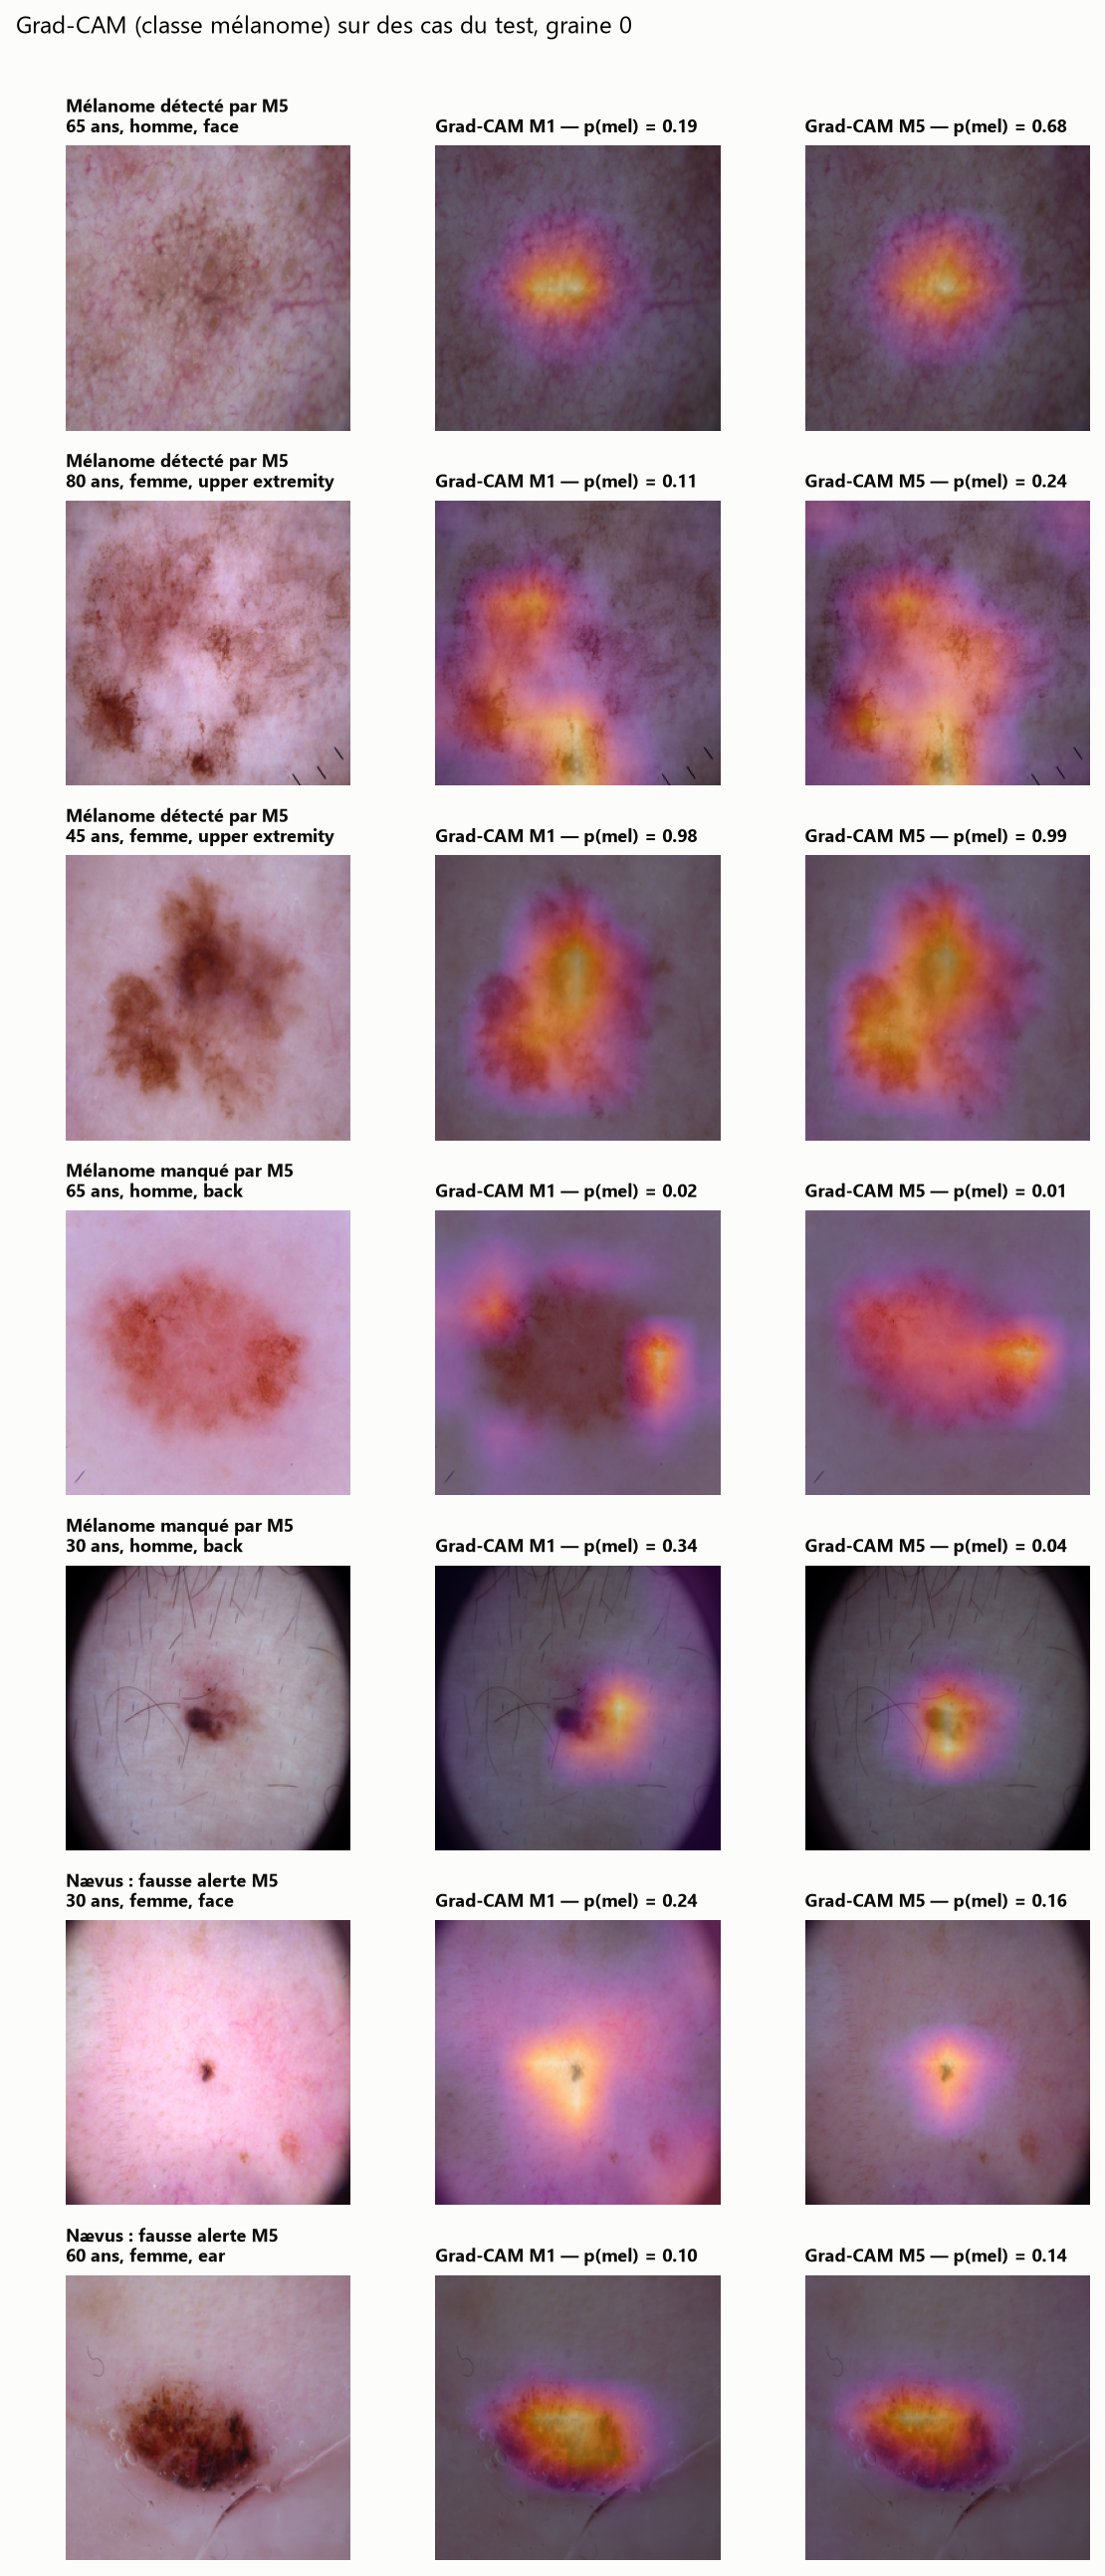

In [17]:
from src import analyses
quiet(analyses.main)               # Grad-CAM, FiLM, contrefactuels, SHAP, sous-groupes, bonus (≈ 2 min sur GPU)
fig("09_gradcam_melanome", 650)

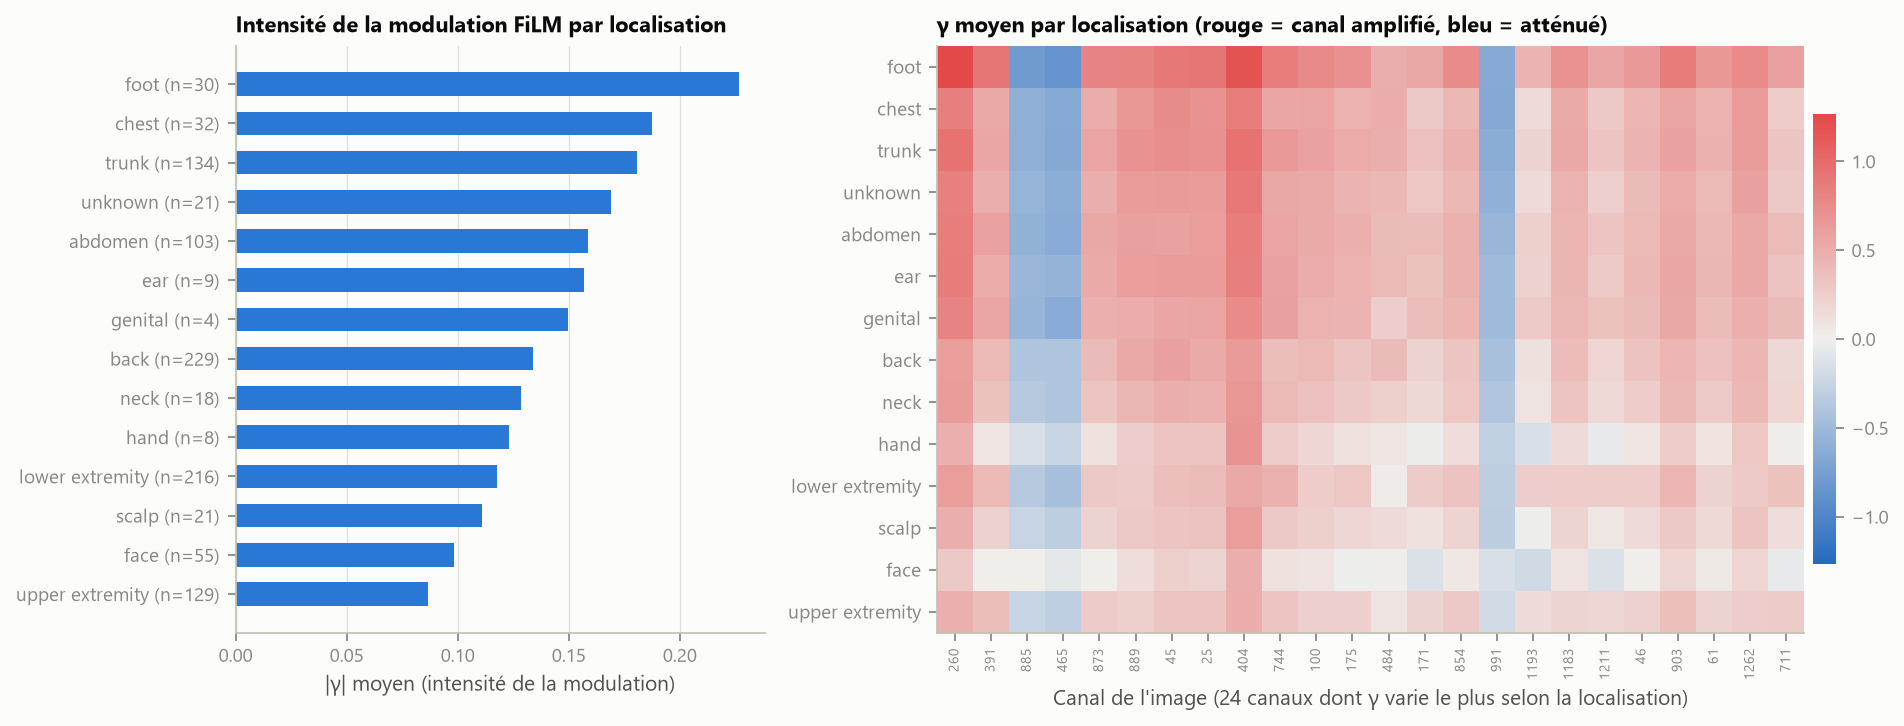

,loc,n,|γ| moyen,|β| moyen
0,upper extremity,129,0.0865,0.0615
1,face,55,0.0981,0.0756
2,scalp,21,0.1111,0.0772
3,lower extremity,216,0.1177,0.0775
4,hand,8,0.1233,0.0878
5,neck,18,0.1284,0.0889
6,back,229,0.1338,0.0988
7,genital,4,0.1494,0.0962
8,ear,9,0.1567,0.1056
9,abdomen,103,0.1587,0.1039


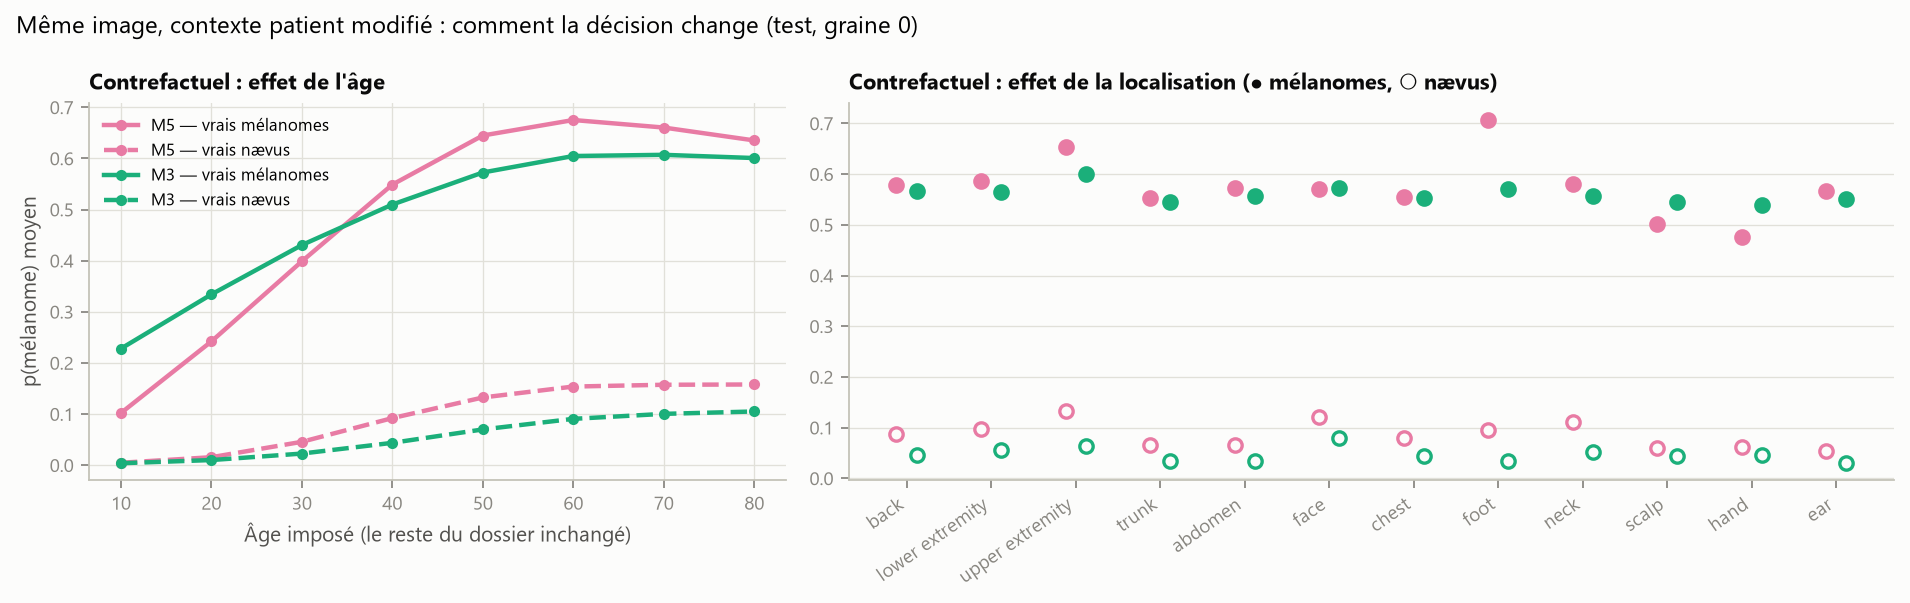

In [18]:
fig("09_film_localisation")
display(tab("09_film_force_par_localisation"))
fig("09_contrefactuels")

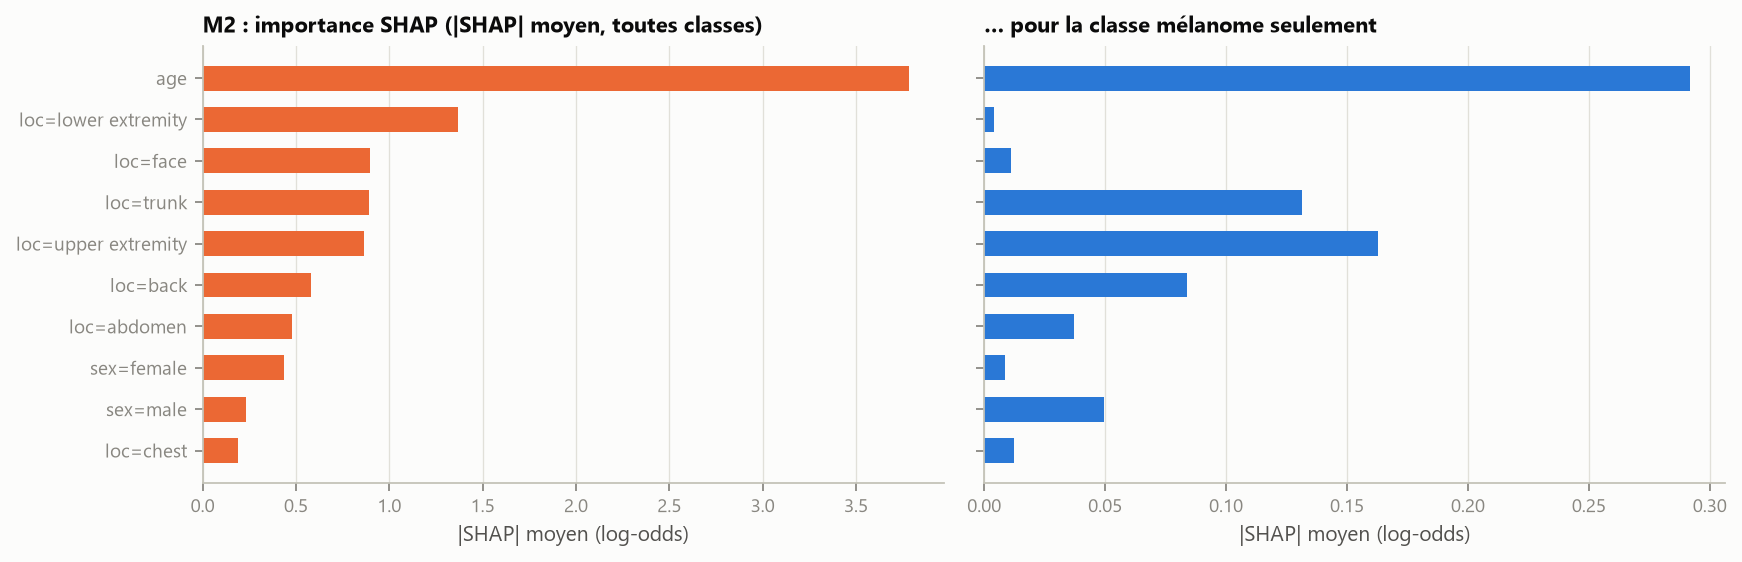

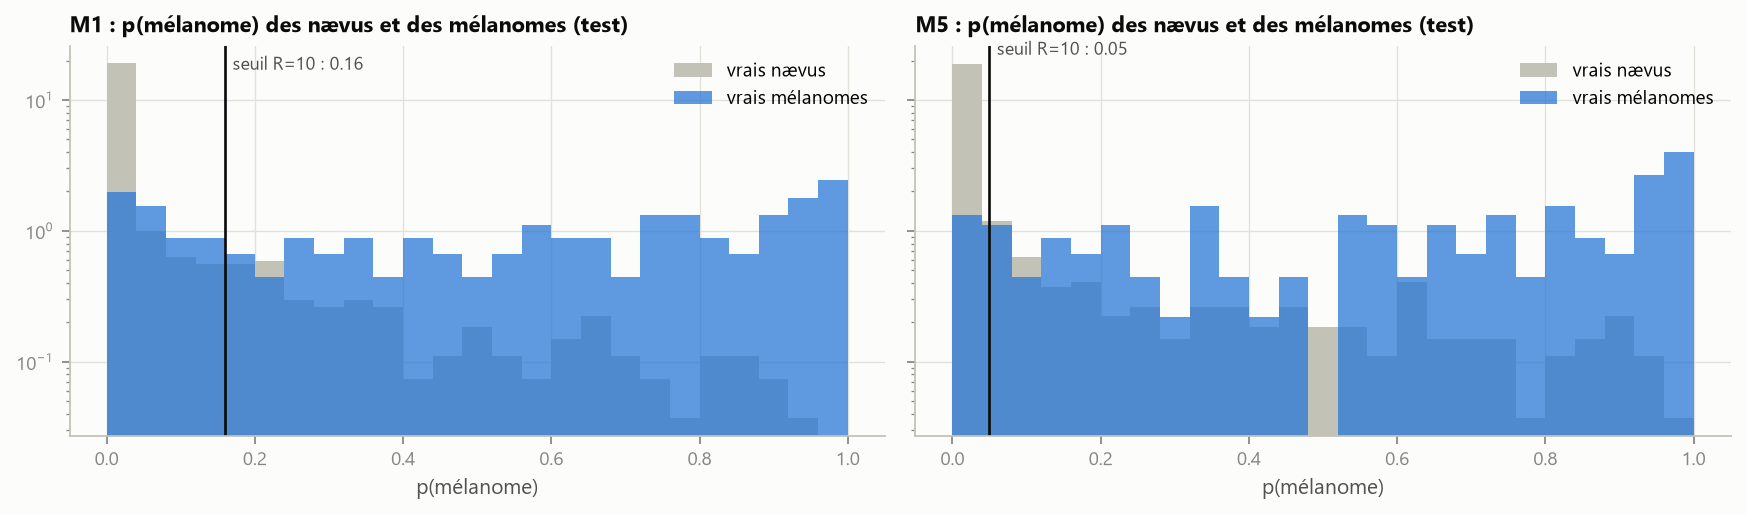

mel → nv  mel → autre bénin  nv → mel  mélanomes  nævus
modèle décision                                                          
M1     classique      29.7               16.3      28.7      113.0  674.0
       coût R=10      16.7                4.7     102.0      113.0  674.0
M5     classique      23.0               14.0      54.3      113.0  674.0
       coût R=10      11.3                2.0     129.0      113.0  674.0

In [19]:
fig("09_shap_M2")
fig("09_mel_vs_nv")
display(tab("09_confusions_mel_nv").groupby(["modèle", "décision"]).mean(numeric_only=True).drop(columns="graine").round(1))

**Lecture**

- **Grad-CAM.** Sur les 7 cas montrés, les deux modèles regardent la lésion elle-même (pas la règle graduée ni le
  cercle du dermoscope). Sur les mélanomes que M5 détecte et que M1 manque, les cartes sont presque identiques mais la
  probabilité change (0,19 → 0,68 ; 0,11 → 0,24) : **c'est le contexte qui fait basculer la décision, pas une autre
  lecture spatiale**. Les deux mélanomes manqués montrés sont une lésion rosée peu pigmentée et une très petite lésion
  chez un patient de 30 ans ; les deux fausses alertes, un petit nævus du visage et un nævus foncé irrégulier de
  l'oreille. Quelques exemples ne prouvent rien en général : Grad-CAM sert ici de contrôle qualitatif.
- **Contrefactuels — l'âge domine.** Pour les mêmes images de mélanome, p(mel) moyen passe de **0,10 à 10 ans à
  0,68 à 60 ans** avec M5 (0,23 → 0,61 avec M3). C'est cliniquement plausible (le mélanome est rare chez l'enfant)
  mais c'est aussi un **risque d'équité** : les mélanomes de patients jeunes sont sous-estimés (étape 10). La
  localisation compte moins ; le pied fait monter p(mel) chez M5 (0,71 contre ~0,57).
- **FiLM.** γ suit un motif commun à toutes les localisations, d'intensité variable : modulation la plus forte pour
  le pied, la poitrine et le tronc, la plus faible pour le visage et le membre supérieur. Les γ atteignent ±1 sur les
  canaux les plus modulés (gain 1 + γ entre ≈ 0 et ≈ 2) : le contexte peut presque éteindre ou doubler un canal.
- **SHAP (M2).** L'âge est de loin la variable la plus importante ; « membre inférieur » pèse surtout pour le
  dermatofibrome (siège typique : les jambes), « visage » pour les kératoses actiniques et bénignes — cohérent avec la
  clinique et avec l'exploration (étape 2).
- **Mélanome / nævus.** C'est la confusion principale. M1 classique : 29,7 mélanomes pris pour des nævus et 28,7
  nævus pris pour des mélanomes (moyenne par graine). M5 au coût : 11,3 mélanomes → nævus mais 129 nævus → mélanome
  (19 % des nævus) : le compromis du seuil, visible sur les histogrammes de p(mel).

## Étape 10 — Limites, sous-groupes et robustesse (bonus)

In [20]:
display(tab("10_sous_groupes", index_col=[0, 1, 2]))
display(tab("10_bonus_contexte_manquant", header=[0, 1], index_col=[0, 1, 2]).round(3))

images  mélanomes  exactitude  sensibilité mel  taux de fausse alerte mel
sous-groupe                           modèle décision                                                                            
vérité : histologie                   M1     classique   549.0      113.0       0.696            0.593                      0.115
                                             coût R=10   549.0      113.0       0.602            0.811                      0.343
vérité : suivi / consensus / confocal M1     classique   460.0        0.0       0.958              NaN                      0.008
                                             coût R=10   460.0        0.0       0.935              NaN                      0.035
sexe : homme                          M1     classique   534.0       74.0       0.786            0.626                      0.080
                                             coût R=10   534.0       74.0       0.737            0.842                      0.201
sexe : femme                          M1     classique   467.0       39.0       0.849            0.530                      0.038
                                             coût R=10   467.0       39.0       0.774            0.752                      0.167
âge < 50                              M1     classique   408.0       22.0       0.898            0.303                      0.033
                                             coût R=10   408.0       22.0       0.819            0.621                      0.148
âge ≥ 50                              M1     classique   596.0       91.0       0.760            0.663                      0.080
                                             coût R=10   596.0       91.0       0.710            0.857                      0.212
vérité : histologie                   M5     classique   549.0      113.0       0.676            0.673                      0.175
                                             coût R=10   549.0      113.0       0.576            0.882                      0.410
vérité : suivi / consensus / confocal M5     classique   460.0        0.0       0.954              NaN                      0.008
                                             coût R=10   460.0        0.0       0.914              NaN                      0.051
sexe : homme                          M5     classique   534.0       74.0       0.774            0.689                      0.104
                                             coût R=10   534.0       74.0       0.700            0.878                      0.257
sexe : femme                          M5     classique   467.0       39.0       0.834            0.641                      0.075
                                             coût R=10   467.0       39.0       0.765            0.889                      0.192
âge < 50                              M5     classique   408.0       22.0       0.886            0.318                      0.054
                                             coût R=10   408.0       22.0       0.809            0.591                      0.158
âge ≥ 50                              M5     classique   596.0       91.0       0.746            0.758                      0.117
                                             coût R=10   596.0       91.0       0.678            0.952                      0.275

F1 macro        Exactitude équilibrée        Sensibilité mel        Spécificité mel        Coût attendu       
                                            mean    std                  mean    std            mean    std            mean    std         mean    std
modèle      test              décision                                                                                                                
M1          contexte complet  classique    0.646  0.023                 0.622  0.017           0.593  0.062           0.940  0.013        0.595  0.069
                              coût R=10    0.590  0.036                 0.571  0.029           0.811  0.022           0.815  0.012        0.436  0.028
M3          contexte complet  classique    0.685  0.006                 0.651  0.010           0.599  0.036           0.944  0.008        0.573  0.040
                              coût R=10    0.617  0.022                 0.588  0.025           0.826  0.052           0.814  0.058        0.411  0.024
            contexte manquant classique    0.622  0.017                 0.558  0.020           0.513  0.062           0.965  0.004        0.669  0.072
                              coût R=10    0.560  0.047                 0.521  0.036           0.785  0.054           0.827  0.057        0.457  0.018
M5          contexte complet  classique    0.674  0.016                 0.673  0.012           0.673  0.015           0.911  0.004        0.527  0.027
                              coût R=10    0.609  0.065                 0.605  0.044           0.882  0.090           0.775  0.082        0.389  0.037
            contexte manquant classique    0.515  0.036                 0.475  0.035           0.189  0.113           0.992  0.001        1.044  0.130
                              coût R=10    0.529  0.006                 0.513  0.015           0.794  0.060           0.850  0.050        0.451  0.041
M5_dropClin contexte complet  classique    0.651  0.042                 0.632  0.036           0.622  0.062           0.929  0.003        0.577  0.087
                              coût R=10    0.602  0.028                 0.587  0.024           0.829  0.034           0.804  0.031        0.427  0.044
            contexte manquant classique    0.629  0.041                 0.617  0.036           0.625  0.036           0.919  0.010        0.591  0.067
                              coût R=10    0.594  0.033                 0.586  0.022           0.861  0.027           0.797  0.010        0.407  0.053

**Bonus — contexte manquant.** Testé sans aucune donnée clinique, **M5 s'effondre** (décision classique : F1 0,515,
sensibilité mélanome **0,189**) : le FiLM a rendu le modèle dépendant du contexte. Entraîné avec **dropout de la
modalité clinique** (contexte masqué 25 % du temps), il reste robuste (F1 0,629 et sensibilité 0,625 sans contexte,
contre 0,651 / 0,622 avec), pour un léger coût avec contexte (F1 0,651 contre 0,674). **Un modèle FiLM déployé là
où le contexte peut manquer doit être entraîné avec ce dropout.**

**Sous-groupes.** Tous les mélanomes du test sont confirmés par histologie ; parmi les lésions bénignes, les fausses
alertes de M5 au coût touchent 41 % des lésions **histologiques** (lésions jugées suspectes et retirées) contre 5 % des
lésions suivies / consensus : les nævus « faciles » du suivi gonflent les performances globales. **Patients de moins de
50 ans** : sensibilité mélanome faible pour tous (M5 au coût 0,59 ; M1 au coût 0,62 ; 22 mélanomes seulement).
Sexe : sensibilité mélanome de M1 classique 0,53 chez les femmes contre 0,63 chez les hommes ; M5 au coût 0,89
(femmes) et 0,88 (hommes) — l'écart disparaît, mais sur 39 et 74 mélanomes seulement.

**Limites**

1. **Déséquilibre et petits effectifs** : 8 lésions de dermatofibrome et 9 de lésions vasculaires au test ; seuils et
   quantiles conformes estimés sur 61 lésions de mélanome (validation) → instabilité entre graines.
2. **Contexte clinique pauvre** (3 variables, âge arrondi à 5 ans) et **codage hétérogène de la localisation** selon
   les centres (« trunk » vs « back/chest/abdomen »).
3. **Deux centres seulement**, peaux majoritairement claires, appareils limités : aucune validation externe
   (ISIC 2019/2020, autres phototypes).
4. **Plusieurs images par lésion** : la garantie conforme suppose l'échangeabilité ; elle tient au niveau lésion mais
   les images d'une même lésion sont corrélées (couverture test 0,889 pour 0,90 visé).
5. **Vérité terrain** : histologie pour ~53 % des images seulement ; le reste par suivi ou consensus.
6. **Dépendance à l'âge** : risque de sous-diagnostic chez les jeunes (contrefactuels, sous-groupes).
7. **Matrice de coût simplifiée** (une seule classe « grave ») et rapport R arbitraire ; une vraie matrice devrait
   être fixée avec des cliniciens.
8. **Ce n'est pas un dispositif médical** : aucun usage diagnostique réel.

## Conclusion

**Réponse à la question de recherche.**

- **Plus sûre : oui, nettement.** Sur 113 mélanomes du test, le classifieur classique (M1) en laisse passer 46 ;
  l'IA prudente complète (M5 + coût + abstention) n'en classe que **6,7 comme bénins sans renvoi**, tout en traitant
  seule 65 % des cas avec 90 % d'exactitude. Le coût attendu baisse de 0,595 à 0,389 sans abstention.
- **Meilleure : pas sur toutes les métriques.** Le F1 macro baisse avec la décision au coût, la spécificité aussi, et
  45 % des cas partent chez le médecin. C'est un **choix de point de fonctionnement**, pas un gain gratuit.
- **D'où vient le gain ?** Surtout de la **couche de décision** (seuil de coût + abstention conforme Mondrian).
  Le **FiLM apporte un supplément modeste mais reproduit** (sensibilité mélanome +0,065 dans deux comparaisons
  indépendantes, mélanomes manqués en silence ≈ 7 contre 10–12), sans gain significatif de discrimination (AUC).
  La perte pondérée est redondante avec le seuil.

**Ce qui reste à faire** : validation externe (ISIC 2019/2020, autres phototypes) ; matrice de coût fixée avec des
dermatologues ; seuil et calibration conforme sur des jeux plus grands (ou validation croisée) ; prédiction conforme
au niveau lésion ; résolution plus élevée et ensembles de modèles ; correction du biais lié à l'âge ; dropout clinique
par défaut ; étude prospective de la charge de travail induite par les renvois.